# Objective = car import price prediction
## Project Overview
* the objective of this project is to develop a machine learning model that predicts the price of car based on its specification and characteristics.
* the dataset contain 200 0bservation and 26 columns,including numerical value and categorical value.
## project objectives 
*  understand the dataset and its feature.
*  perform EDA
*  Identify outliers,null values and relationship between variables.
*  Preprocess the dataset.
*  Train and compare multiple regression models.
*  Optimize hyperparameters using GridSearchCV.
*  predict car prices for new observations.
## Target Varible
* The target variable is price of the car.
## Project Workflow
1. Data loading
2. Data Understanding
3. EDA
4. Data Preprocessing
5. Feature Selection
6. Model Training
7. Hyperparameter Tunning
8. Model evaluation
9. Final prediction

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_palette("muted")

### Loading Datasets

In [2]:
df_all = pd.read_csv("auto_imports.csv")

### df all
-it is complete dataset

In [3]:
df_all.head()

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250


In [4]:
df_all.tail()

,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
195,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
196,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
197,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
198,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470
199,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625


In [5]:
df_all.columns

Index(['3', '?', 'alfa-romero', 'gas', 'std', 'two', 'convertible', 'rwd',
       'front', '88.60', '168.80', '64.10', '48.80', '2548', 'dohc', 'four',
       '130', 'mpfi', '3.47', '2.68', '9.00', '111', '5000', '21', '27',
       '13495'],
      dtype='object')

### Our Dataset doesnt have any column name.
### lets give its column name

In [6]:
df_all.columns = ["symboling", "normalized-losses", "car_name", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location",
    "wheel-base", "length", "width", "height", "curb-weight",
    "engine-type", "num-of-cylinders", "engine-size", "fuel-system",
    "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"]

### Dataset have some null value in the form of '?'
###  change it to null values

In [7]:
(df_all == "?").sum()

symboling             0
normalized-losses    36
car_name              0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

In [8]:
df_all = df_all.replace("?",np.nan)

# Basic Understanding of Data

1. checking dimensions

In [9]:
df_all.shape

(200, 26)

2. checking for null values

In [10]:
df_all.isnull().sum()

symboling             0
normalized-losses    36
car_name              0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

3. Checking for duplicates

In [11]:
df_all.duplicated().sum() 

np.int64(0)

4. Checking for the data types

In [12]:
df_all.dtypes

symboling              int64
normalized-losses     object
car_name              object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                  object
stroke                object
compression-ratio    float64
horsepower            object
peak-rpm              object
city-mpg               int64
highway-mpg            int64
price                  int64
dtype: object

In [13]:
df_all["num-of-doors"].map(type).value_counts()

num-of-doors
<class 'str'>      198
<class 'float'>      2
Name: count, dtype: int64

In [14]:
df_all["num-of-cylinders"].map(type).value_counts()

num-of-cylinders
<class 'str'>    200
Name: count, dtype: int64

In [15]:
df_all["bore"].map(type).value_counts()

bore
<class 'str'>      196
<class 'float'>      4
Name: count, dtype: int64

In [16]:
df_all["horsepower"].map(type).value_counts()

horsepower
<class 'str'>      198
<class 'float'>      2
Name: count, dtype: int64

In [17]:
df_all["peak-rpm"].map(type).value_counts()

peak-rpm
<class 'str'>      198
<class 'float'>      2
Name: count, dtype: int64

In [18]:
df_all["stroke"].map(type).value_counts()

stroke
<class 'str'>      196
<class 'float'>      4
Name: count, dtype: int64

## Insight
* Peak-Rpm,Horsepower,Bore and Stroke have some values in string but they are numerical features.
* so we will change ti to numerical column.

In [19]:
cols = ['bore', 'stroke', 'horsepower', 'peak-rpm']

df_all[cols] = df_all[cols].apply(pd.to_numeric, errors='coerce')

In [20]:
df_all.dtypes

symboling              int64
normalized-losses     object
car_name              object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                  int64
dtype: object

5. checking the basic information of dataset

In [21]:
df_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          200 non-null    int64  
 1   normalized-losses  164 non-null    object 
 2   car_name           200 non-null    object 
 3   fuel-type          200 non-null    object 
 4   aspiration         200 non-null    object 
 5   num-of-doors       198 non-null    object 
 6   body-style         200 non-null    object 
 7   drive-wheels       200 non-null    object 
 8   engine-location    200 non-null    object 
 9   wheel-base         200 non-null    float64
 10  length             200 non-null    float64
 11  width              200 non-null    float64
 12  height             200 non-null    float64
 13  curb-weight        200 non-null    int64  
 14  engine-type        200 non-null    object 
 15  num-of-cylinders   200 non-null    object 
 16  engine-size        200 non

## Observation
1. This dataset consit of 200 rows and 26 columns.
2. There are 10 categorical and 16 numerical attributes.
3. All the features have correct data-types.
4. There are 36 missing values in normalized-losses,2 in num-of-doors,4 in bore and stroke each and 2 values missing in horsepower and peak-rpm.
5. There are no duplicate record.

## Spliting our whole data to avoid leakage.

In [22]:
from sklearn.model_selection import train_test_split
X = df_all.drop('price',axis = 1)
Y = df_all["price"]

X_train,X_test,Y_train,Y_test = train_test_split(X,Y, test_size = 0.2,random_state = 43)


## Storing x_train and y_train in single variable to perform EDA easily.

In [23]:
df = pd.concat([X_train,Y_train],axis = 1)   #here we created a df which contain both x_tain and y_train

In [24]:
null_compare = pd.concat(
    [df_all.isnull().sum(), df.isnull().sum()],
    axis=1,
    keys=['all', 'train']
)

null_compare[(null_compare['all'] > 0) | (null_compare['train'] > 0)]

,all,train
normalized-losses,36,26
num-of-doors,2,2
bore,4,4
stroke,4,4
horsepower,2,2
peak-rpm,2,2


### Checking for missing values in our train data

In [25]:
df.isnull().sum()

symboling             0
normalized-losses    26
car_name              0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

In [26]:
df.describe()

,symboling,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,156.000000,156.000000,160.000000,158.000000,158.000000,160.000000,160.000000,160.000000
mean,0.812500,98.967500,174.183125,65.917500,53.843125,2550.968750,125.050000,3.328333,3.250833,10.211937,102.405063,5125.000000,25.287500,30.750000,12918.087500
std,1.219277,6.042143,12.547215,2.047503,2.459652,520.551285,40.560352,0.273295,0.320821,4.154144,36.793976,481.529874,6.674261,7.077291,7873.467604
min,-2.000000,86.600000,141.100000,60.300000,49.400000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,14.000000,16.000000,5151.000000
25%,0.000000,94.500000,166.300000,64.200000,52.000000,2143.750000,97.000000,3.117500,3.117500,8.500000,70.000000,4800.000000,19.000000,25.000000,7725.750000
50%,1.000000,97.000000,173.000000,65.500000,54.100000,2414.000000,110.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.500000,30.000000,9988.500000
75%,2.000000,102.475000,185.100000,66.900000,55.700000,3013.000000,141.000000,3.612500,3.410000,9.400000,116.000000,5500.000000,30.000000,34.500000,15988.250000
max,3.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,308.000000,3.800000,4.170000,23.000000,207.000000,6600.000000,49.000000,54.000000,45400.000000


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 160 entries, 116 to 68
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          160 non-null    int64  
 1   normalized-losses  134 non-null    object 
 2   car_name           160 non-null    object 
 3   fuel-type          160 non-null    object 
 4   aspiration         160 non-null    object 
 5   num-of-doors       158 non-null    object 
 6   body-style         160 non-null    object 
 7   drive-wheels       160 non-null    object 
 8   engine-location    160 non-null    object 
 9   wheel-base         160 non-null    float64
 10  length             160 non-null    float64
 11  width              160 non-null    float64
 12  height             160 non-null    float64
 13  curb-weight        160 non-null    int64  
 14  engine-type        160 non-null    object 
 15  num-of-cylinders   160 non-null    object 
 16  engine-size        160 non-nul

# Performing EDA

## Univarient Analysis

## Visualizing our target feature.

In [28]:
%matplotlib inline
sns.set(style="darkgrid",font_scale=1.5) #setting grid design in our graph
pd.set_option("display.max.columns",None)
pd.set_option("display.max.rows",None)


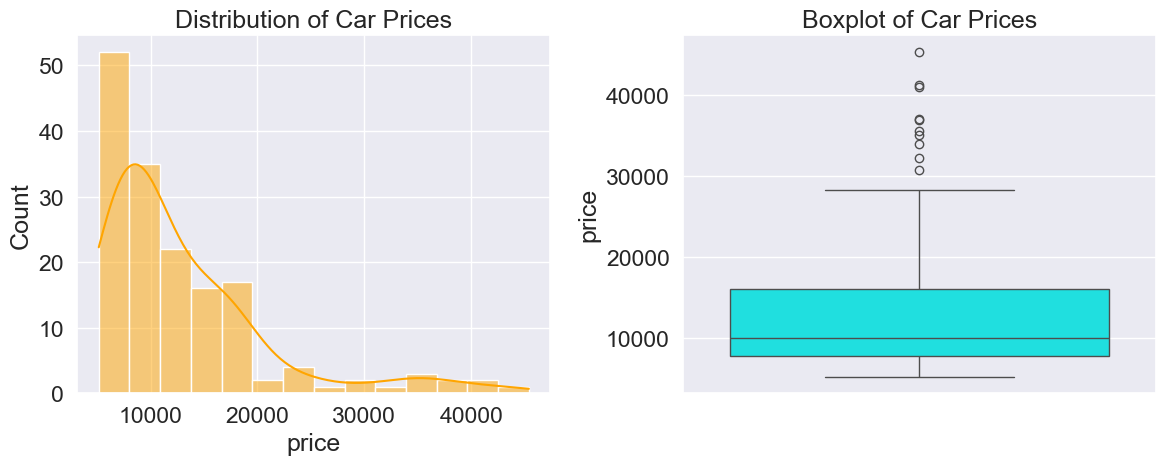

In [29]:

plt.figure(figsize=(12, 5))

# Histogram
plt.subplot(1, 2, 1)
sns.histplot(data=df, x='price', kde=True,color = 'orange')
plt.title('Distribution of Car Prices')


plt.subplot(1, 2, 2)
sns.boxplot(data=df, y='price',color = 'cyan')
plt.title('Boxplot of Car Prices')

plt.tight_layout()
plt.show()

In [30]:
df["price"].describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
price,160.0,12918.0875,7873.467604,5151.0,7725.75,9988.5,15988.25,45400.0


In [31]:
df["price"].skew()

np.float64(1.9828667846575827)

### Insight
1. We observed that our **Car Price feature** is Rightly Skewed.
2. We can clearly observe that there is clear difference between mean & meadian value.
3. We can also see that most of the **car'price is below 13000**.
4. **skewness** is also above **1.5** which means that it is highly spread.

In [32]:
numerical_col = X_train.select_dtypes(include = np.number).columns
numerical_col

Index(['symboling', 'wheel-base', 'length', 'width', 'height', 'curb-weight',
       'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower',
       'peak-rpm', 'city-mpg', 'highway-mpg'],
      dtype='object')

In [33]:
categorical_col = X_train.select_dtypes(exclude = np.number).columns
categorical_col

Index(['normalized-losses', 'car_name', 'fuel-type', 'aspiration',
       'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
       'engine-type', 'num-of-cylinders', 'fuel-system'],
      dtype='object')

In [34]:
X_train[numerical_col].describe()

,symboling,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg
count,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,156.000000,156.000000,160.000000,158.000000,158.000000,160.000000,160.000000
mean,0.812500,98.967500,174.183125,65.917500,53.843125,2550.968750,125.050000,3.328333,3.250833,10.211937,102.405063,5125.000000,25.287500,30.750000
std,1.219277,6.042143,12.547215,2.047503,2.459652,520.551285,40.560352,0.273295,0.320821,4.154144,36.793976,481.529874,6.674261,7.077291
min,-2.000000,86.600000,141.100000,60.300000,49.400000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,14.000000,16.000000
25%,0.000000,94.500000,166.300000,64.200000,52.000000,2143.750000,97.000000,3.117500,3.117500,8.500000,70.000000,4800.000000,19.000000,25.000000
50%,1.000000,97.000000,173.000000,65.500000,54.100000,2414.000000,110.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.500000,30.000000
75%,2.000000,102.475000,185.100000,66.900000,55.700000,3013.000000,141.000000,3.612500,3.410000,9.400000,116.000000,5500.000000,30.000000,34.500000
max,3.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,308.000000,3.800000,4.170000,23.000000,207.000000,6600.000000,49.000000,54.000000


# Visualizing all the categorical columns.

## Car-name

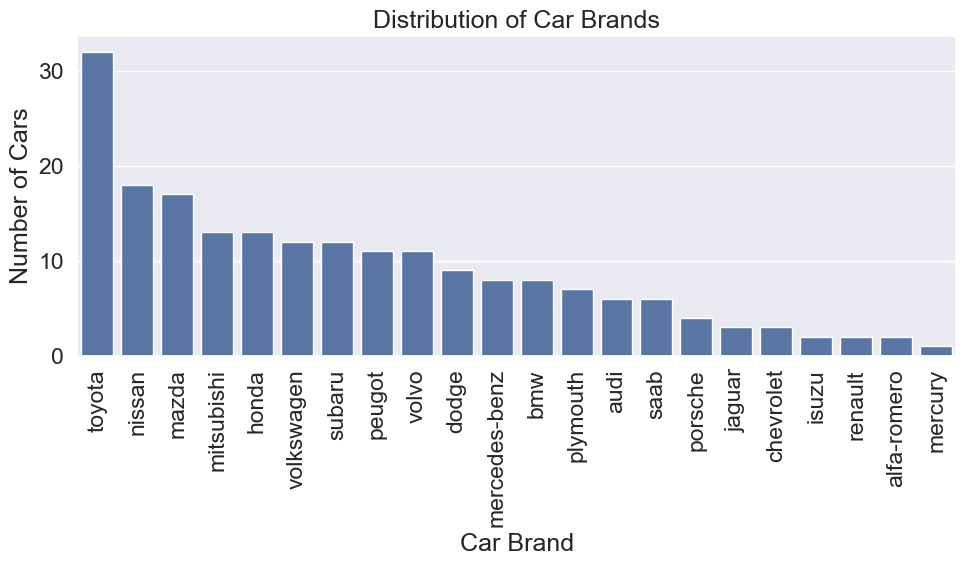

In [35]:
plt.figure(figsize=(10, 6))

order = df_all["car_name"].value_counts().index

sns.countplot(
    data=df_all,
    x="car_name",
    order=order
)

plt.title("Distribution of Car Brands")
plt.xlabel("Car Brand")
plt.ylabel("Number of Cars")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### insights
1. Toyota has sold the highest number of car.
2. It means Toyota have highest customer retention.
3. Mercury,Alfa-romeo,Renault and Isuzu have lowest sale of cars.

### Bivariant analysis of car_name with respect to Price

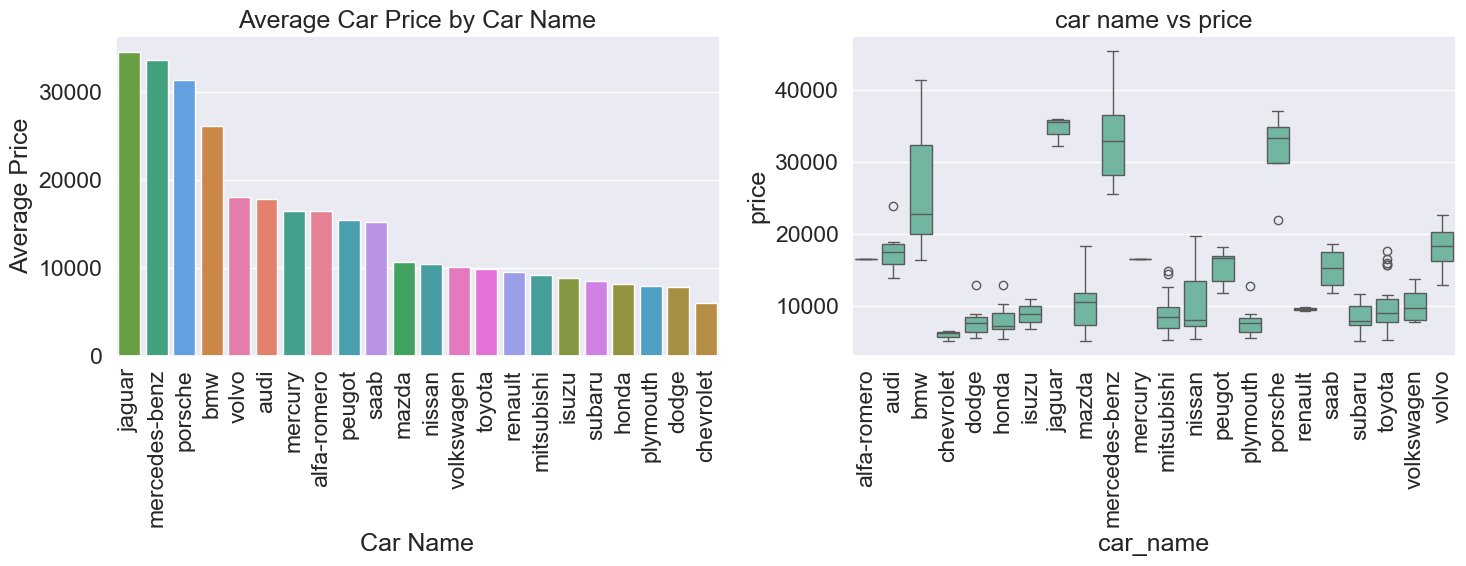

In [36]:
sns.set_palette("Set2")
plt.figure(figsize=(15, 6))

order = df_all.groupby("car_name")["price"].mean().sort_values(ascending=False).index
plt.subplot(1,2,1)
sns.barplot(data=df_all,x="car_name",y="price",order=order,hue="car_name",legend=False,errorbar=None
)

plt.title("Average Car Price by Car Name")
plt.xlabel("Car Name")
plt.ylabel("Average Price")
plt.xticks(rotation=90)

plt.subplot(1,2,2)
sns.boxplot(x=df_all["car_name"],y=df_all["price"])
plt.xticks(rotation=90)
plt.title("car name vs price")
plt.tight_layout()
plt.show()

In [37]:
df_all[df_all['car_name'] == "chevrolet"]


,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
16,2,121,chevrolet,gas,std,two,hatchback,fwd,front,88.4,141.1,60.3,53.2,1488,l,three,61,2bbl,2.91,3.03,9.5,48.0,5100.0,47,53,5151
17,1,98,chevrolet,gas,std,two,hatchback,fwd,front,94.5,155.9,63.6,52.0,1874,ohc,four,90,2bbl,3.03,3.11,9.6,70.0,5400.0,38,43,6295
18,0,81,chevrolet,gas,std,four,sedan,fwd,front,94.5,158.8,63.6,52.0,1909,ohc,four,90,2bbl,3.03,3.11,9.6,70.0,5400.0,38,43,6575


In [38]:
df_all[df_all["car_name"]=="renault"]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
125,0,NaN,renault,gas,std,four,wagon,fwd,front,96.1,181.5,66.5,55.2,2579,ohc,four,132,mpfi,3.46,3.9,8.7,NaN,NaN,23,31,9295
126,2,NaN,renault,gas,std,two,hatchback,fwd,front,96.1,176.8,66.6,50.5,2460,ohc,four,132,mpfi,3.46,3.9,8.7,NaN,NaN,23,31,9895


## Insights
1. Jaguar & buick seems to have the highest price range cars.
2. Companies like Nissan,Renault,Mercury and chevrole have only 1-3 datapoints.
3. We can derive a new feature such as LowRange,Medium Range,High Range.

## 2.Fuel-Type

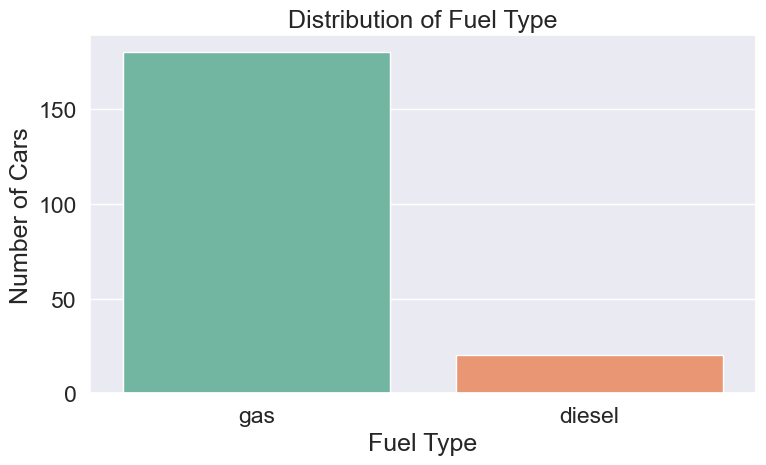

In [39]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_all,
    x="fuel-type",
    hue="fuel-type",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

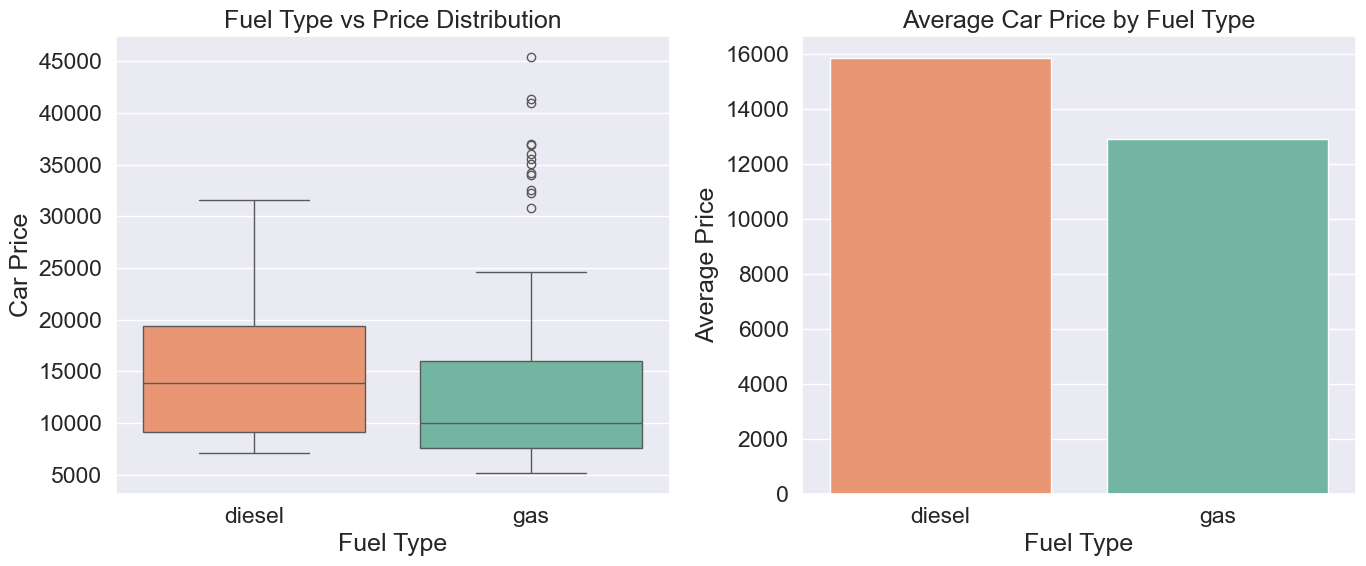

In [40]:
plt.figure(figsize=(14, 6))

order = df_all.groupby("fuel-type")["price"].mean().sort_values(ascending=False).index

# Boxplot
plt.subplot(1, 2, 1)

sns.boxplot(
    data=df_all,
    x="fuel-type",
    y="price",
    hue="fuel-type",
    order=order,
    palette="Set2",
    legend=False
)

plt.title("Fuel Type vs Price Distribution")
plt.xlabel("Fuel Type")
plt.ylabel("Car Price")

# Barplot
plt.subplot(1, 2, 2)

sns.barplot(
    data=df_all,
    x="fuel-type",
    y="price",
    hue="fuel-type",
    order=order,
    palette="Set2",
    legend=False,
    errorbar=None
)

plt.title("Average Car Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Price")

plt.tight_layout()
plt.show()

### Insights
1. Car having gas fuel system is moslty sold.
2. We can also see that gas fuel cars are available within every price range.
3. Average price of gas fuel car less than Diesel cars.
4. Consumer prefer those car which consumes less price in fuel

In [41]:
def cg(cols):
    plt.figure(figsize=(15,6))
    plt.subplot(1,3,1)
    order = df_all.groupby(cols)["price"].mean().sort_values(ascending=False).index
    sns.countplot(x=cols,data=df_all,hue=cols,legend=False,palette="colorblind")
    plt.title(f"{cols} Distribution",pad=10,fontweight="black",fontsize=18)
    plt.xticks(rotation=90)
    total = df_all[cols].notna().sum()
    for container in plt.gca().containers:
        plt.gca().bar_label(container, fmt=lambda x: f'{x/total*100:.1f}%', padding=3)
    

    plt.subplot(1,3,2)
    sns.boxplot(x=cols,y="price",data=df_all,hue=cols,legend=False,palette="colorblind")
    plt.xticks(rotation=90)
    plt.title(f"{cols} vs Price",pad=20,fontweight="black",fontsize=18)
    
    
    plt.subplot(1,3,3)
    sns.barplot(x=cols,y='price',data=df_all,hue=cols,errorbar=None,legend=False,palette="colorblind",order=order)
    plt.ylabel("average price")
    plt.xticks(rotation=90)
    plt.title(f"{cols} vs Average Price",pad=20,fontweight="black",fontsize=18)
    plt.tight_layout()
    plt.show()

## 3.ASPIRATION

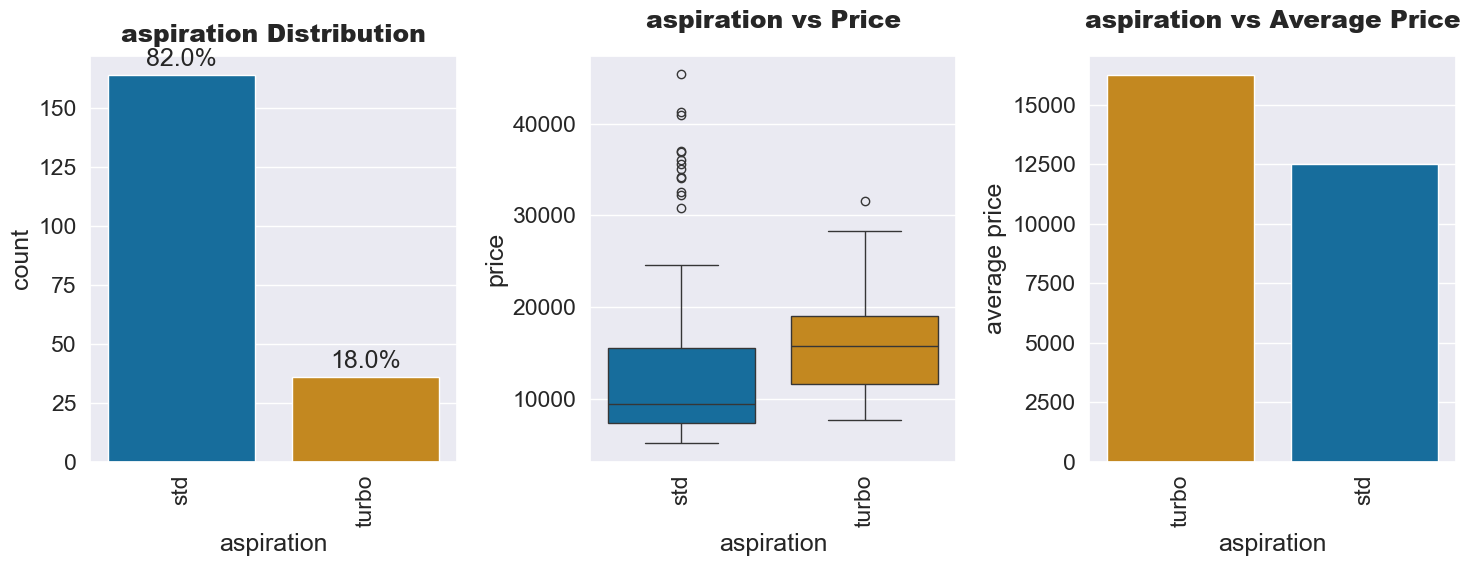

In [42]:
cg('aspiration')

## Observations
1. standard aspiration cars are highly sold.
2. Turbo aspirated cars are more expensive than std.
3. But some STD aspirated car are expensive too.

## 4. num of doors

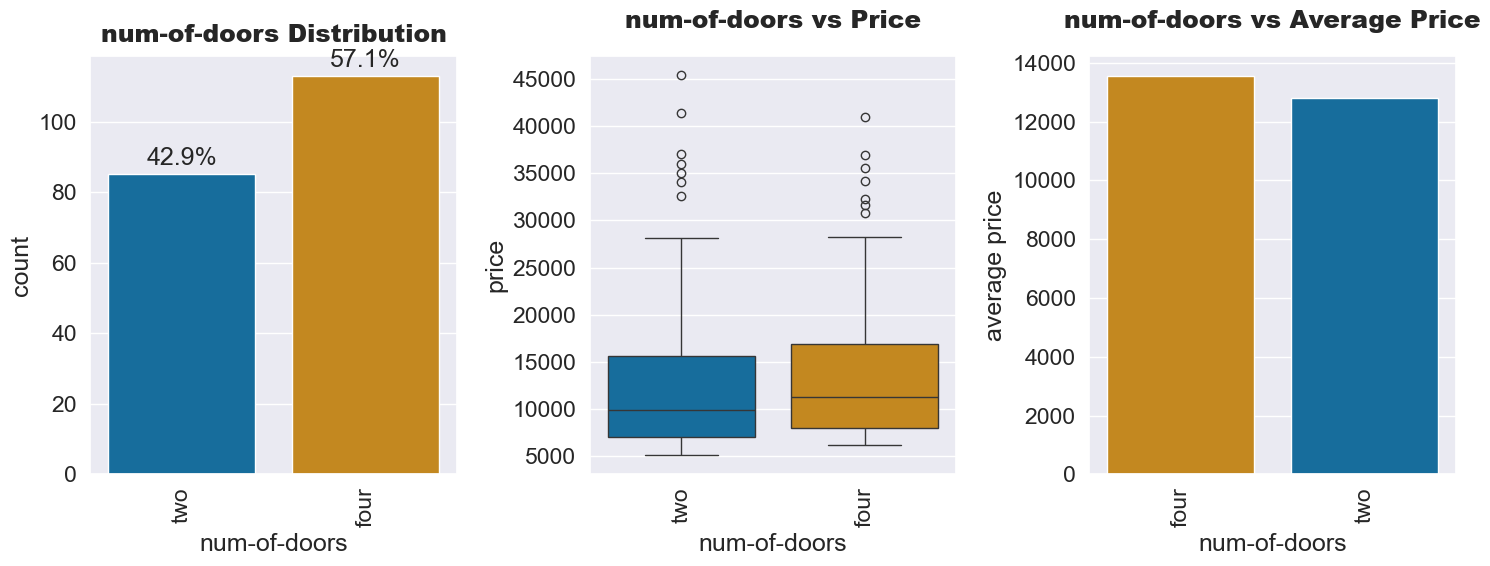

In [43]:
cg('num-of-doors')

## observation
1. Four doors cars are sold more.
2. Cars having Fours Doors are little more expensive when we compare the avergae price of cars having two doors or four doors.
3. Outliers prsesent in two doors cars states that some of the cars are are more expensive than the cars having four doors.
4. This category is not affceting the car price much.

# 5. Car body style.

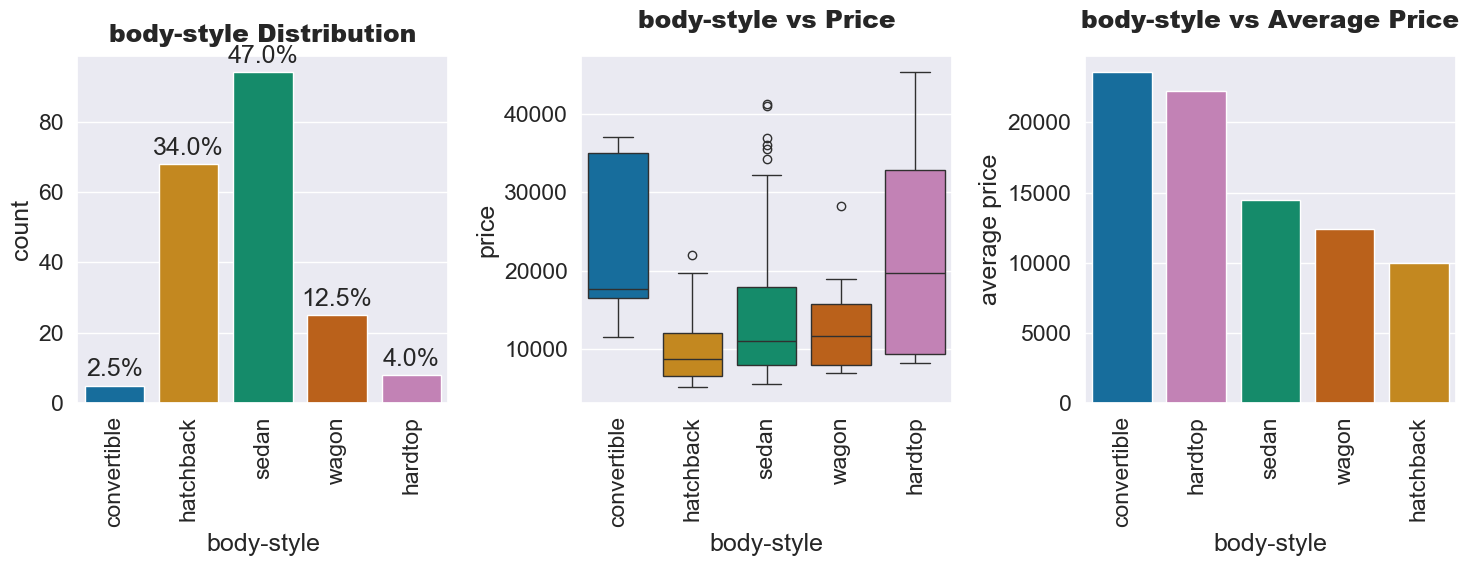

In [44]:
cg("body-style")

# Observations:-
1. Sedans are the most selling cars and after it hatchbacks are sold the most.
2. Cars having convertible or hardtop body-type are less sold.
3. Cars having convertible body are mostly expensive followed by hardtop.
4. Convertible & Hardtop body-types are less sold because they are very expensive cars. So most of the customers couldn't prefer it.
5. Cars having Sedan body-type is the third most expensive car. But still its having the most number of car sales. So we can say customers prefer medium price range cars.

## 6. Drive wheels

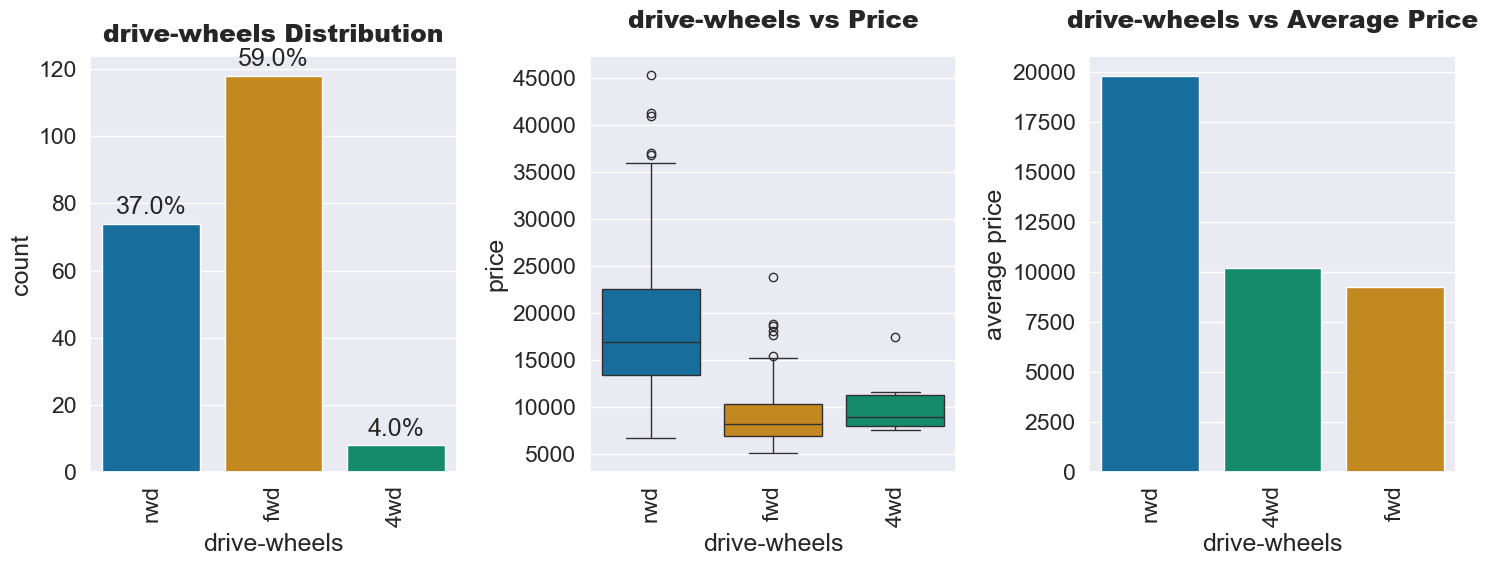

In [45]:
cg("drive-wheels")

In [46]:
df_all[df_all["drive-wheels"]=="4wd"]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450
135,2,83,subaru,gas,std,two,hatchback,4wd,front,93.3,157.3,63.8,55.7,2240,ohcf,four,108,2bbl,3.62,2.64,8.7,73.0,4400.0,26,31,7603
139,0,102,subaru,gas,std,four,sedan,4wd,front,97.0,172.0,65.4,54.3,2385,ohcf,four,108,2bbl,3.62,2.64,9.0,82.0,4800.0,24,25,9233
140,0,102,subaru,gas,turbo,four,sedan,4wd,front,97.0,172.0,65.4,54.3,2510,ohcf,four,108,mpfi,3.62,2.64,7.7,111.0,4800.0,24,29,11259
143,0,85,subaru,gas,std,four,wagon,4wd,front,96.9,173.6,65.4,54.9,2420,ohcf,four,108,2bbl,3.62,2.64,9.0,82.0,4800.0,23,29,8013
144,0,85,subaru,gas,turbo,four,wagon,4wd,front,96.9,173.6,65.4,54.9,2650,ohcf,four,108,mpfi,3.62,2.64,7.7,111.0,4800.0,23,23,11694
149,0,81,toyota,gas,std,four,wagon,4wd,front,95.7,169.7,63.6,59.1,2290,ohc,four,92,2bbl,3.05,3.03,9.0,62.0,4800.0,27,32,7898
150,0,91,toyota,gas,std,four,wagon,4wd,front,95.7,169.7,63.6,59.1,3110,ohc,four,92,2bbl,3.05,3.03,9.0,62.0,4800.0,27,32,8778


## observation
1. most of the cars are FWD followed by rwd and there are only 7 4wd cars.
2. Cars with rwd are mostly expensive and fwd cars are cheapest.
3. We can make an insight that the high rated cars must be using Rear Wheel Drive.
4. Cars with low prices must be using Forward Wheel Drive


## 7. engine-location

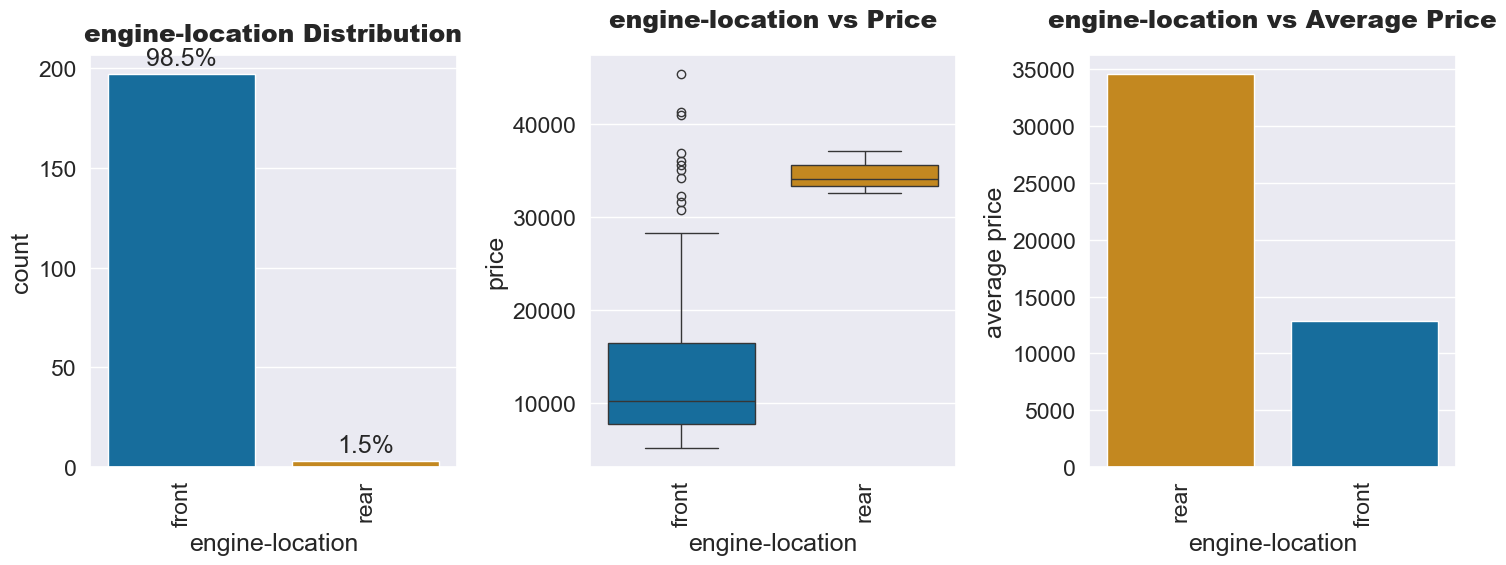

In [47]:
cg("engine-location")

In [48]:
df_all[df_all["engine-location"]=="rear"]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
122,3,NaN,porsche,gas,std,two,hardtop,rwd,rear,89.5,168.9,65.0,51.6,2756,ohcf,six,194,mpfi,3.74,2.9,9.5,207.0,5900.0,17,25,32528
123,3,NaN,porsche,gas,std,two,hardtop,rwd,rear,89.5,168.9,65.0,51.6,2756,ohcf,six,194,mpfi,3.74,2.9,9.5,207.0,5900.0,17,25,34028
124,3,NaN,porsche,gas,std,two,convertible,rwd,rear,89.5,168.9,65.0,51.6,2800,ohcf,six,194,mpfi,3.74,2.9,9.5,207.0,5900.0,17,25,37028


### Observation
1. Almost every car have engine in the front and only three cars have engine in the back.
2. We can removing this feature as this may leads to overfitting.

## 8. Engine-Type

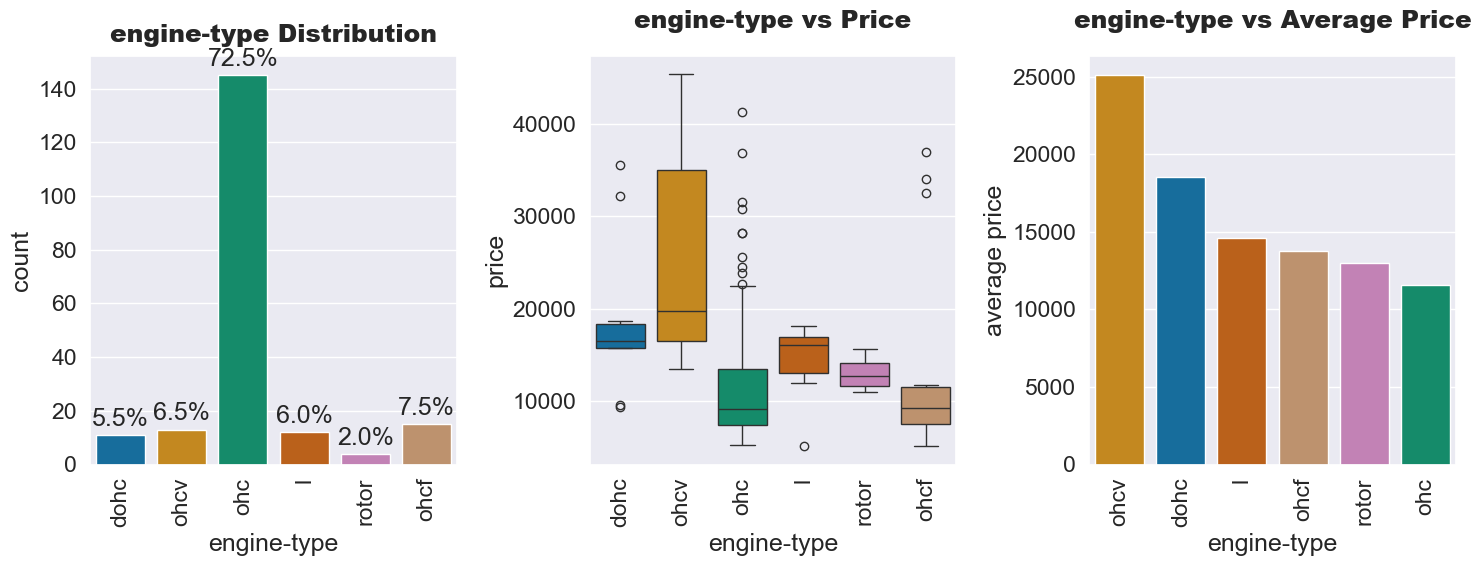

In [49]:
cg("engine-type")

In [50]:
df_all[df_all["engine-type"]=="rotor"]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
51,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2380,rotor,two,70,4bbl,NaN,NaN,9.4,101.0,6000.0,17,23,10945
52,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2380,rotor,two,70,4bbl,NaN,NaN,9.4,101.0,6000.0,17,23,11845
53,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2385,rotor,two,70,4bbl,NaN,NaN,9.4,101.0,6000.0,17,23,13645
54,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2500,rotor,two,80,mpfi,NaN,NaN,9.4,135.0,6000.0,16,23,15645


In [51]:
df_all[df_all["engine-type"]=="dohc"]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
43,0,145,jaguar,gas,std,four,sedan,rwd,front,113.0,199.6,69.6,52.8,4066,dohc,six,258,mpfi,3.63,4.17,8.1,176.0,4750.0,15,19,32250
44,0,NaN,jaguar,gas,std,four,sedan,rwd,front,113.0,199.6,69.6,52.8,4066,dohc,six,258,mpfi,3.63,4.17,8.1,176.0,4750.0,15,19,35550
131,3,150,saab,gas,turbo,two,hatchback,fwd,front,99.1,186.6,66.5,56.1,2808,dohc,four,121,mpfi,3.54,3.07,9.0,160.0,5500.0,19,26,18150
132,2,104,saab,gas,turbo,four,sedan,fwd,front,99.1,186.6,66.5,56.1,2847,dohc,four,121,mpfi,3.54,3.07,9.0,160.0,5500.0,19,26,18620
160,1,168,toyota,gas,std,two,sedan,rwd,front,94.5,168.7,64.0,52.6,2265,dohc,four,98,mpfi,3.24,3.08,9.4,112.0,6600.0,26,29,9298
161,1,168,toyota,gas,std,two,hatchback,rwd,front,94.5,168.7,64.0,52.6,2300,dohc,four,98,mpfi,3.24,3.08,9.4,112.0,6600.0,26,29,9538
173,3,197,toyota,gas,std,two,hatchback,rwd,front,102.9,183.5,67.7,52.0,2976,dohc,six,171,mpfi,3.27,3.35,9.3,161.0,5200.0,20,24,16558
174,3,197,toyota,gas,std,two,hatchback,rwd,front,102.9,183.5,67.7,52.0,3016,dohc,six,171,mpfi,3.27,3.35,9.3,161.0,5200.0,19,24,15998
175,-1,90,toyota,gas,std,four,sedan,rwd,front,104.5,187.8,66.5,54.1,3131,dohc,six,171,mpfi,3.27,3.35,9.2,156.0,5200.0,20,24,15690


## Observation
1. Cars having Overhead Camshaft (OHC) engines are mostly sold , rotor cars are only 4 and dohc engine type car are 10 in number.
2. There are very few data-points of engine type dohcv & rotor. So we can say that cars having ohcv engine types are mostly expensive.
3. Cars hvaing Overhead Camshaft (OHC) engines are least expensive cars,but some (OHC) cars are expensive.

## 9. Cylinder numbers.

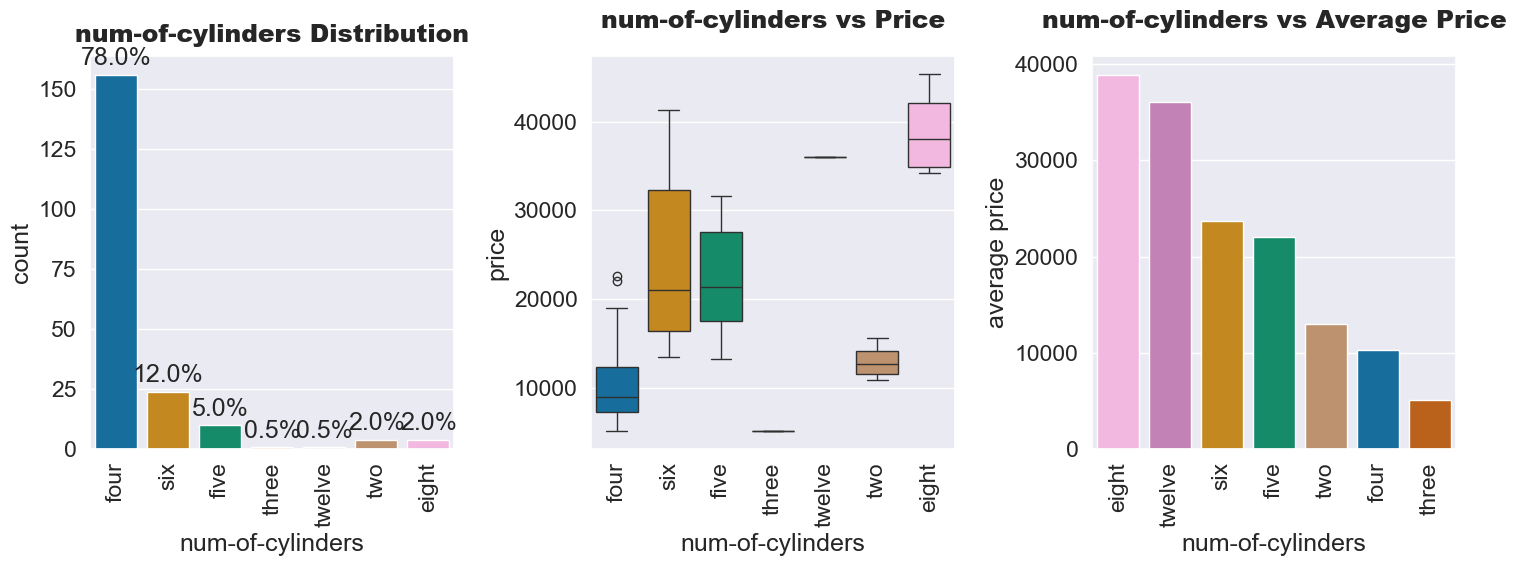

In [52]:
cg('num-of-cylinders')

In [53]:
df_all[df_all["num-of-cylinders"].isin(["three","twelve"])]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
16,2,121,chevrolet,gas,std,two,hatchback,fwd,front,88.4,141.1,60.3,53.2,1488,l,three,61,2bbl,2.91,3.03,9.5,48.0,5100.0,47,53,5151
45,0,NaN,jaguar,gas,std,two,sedan,rwd,front,102.0,191.7,70.6,47.8,3950,ohcv,twelve,326,mpfi,3.54,2.76,11.5,262.0,5000.0,13,17,36000


In [54]:
df_all[df_all["num-of-cylinders"].isin(["two","eight"])]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
51,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2380,rotor,two,70,4bbl,NaN,NaN,9.4,101.0,6000.0,17,23,10945
52,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2380,rotor,two,70,4bbl,NaN,NaN,9.4,101.0,6000.0,17,23,11845
53,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2385,rotor,two,70,4bbl,NaN,NaN,9.4,101.0,6000.0,17,23,13645
54,3,150,mazda,gas,std,two,hatchback,rwd,front,95.3,169.0,65.7,49.6,2500,rotor,two,80,mpfi,NaN,NaN,9.4,135.0,6000.0,16,23,15645
67,-1,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,115.6,202.6,71.7,56.5,3740,ohcv,eight,234,mpfi,3.46,3.10,8.3,155.0,4750.0,16,18,34184
68,3,142,mercedes-benz,gas,std,two,convertible,rwd,front,96.6,180.3,70.5,50.8,3685,ohcv,eight,234,mpfi,3.46,3.10,8.3,155.0,4750.0,16,18,35056
69,0,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,208.1,71.7,56.7,3900,ohcv,eight,308,mpfi,3.80,3.35,8.0,184.0,4500.0,14,16,40960
70,1,NaN,mercedes-benz,gas,std,two,hardtop,rwd,front,112.0,199.2,72.0,55.4,3715,ohcv,eight,304,mpfi,3.80,3.35,8.0,184.0,4500.0,14,16,45400


### Observations
1. Most of the cars are four cylinders.
2. There are only one data-point each for car having Three & Twelve data-points.
3. There are only four data-point each for each two and eight cylinders car.
4. Cars having eight cyclinders are most expensive cars followed by six cyclinders.

## 10. Fuel system

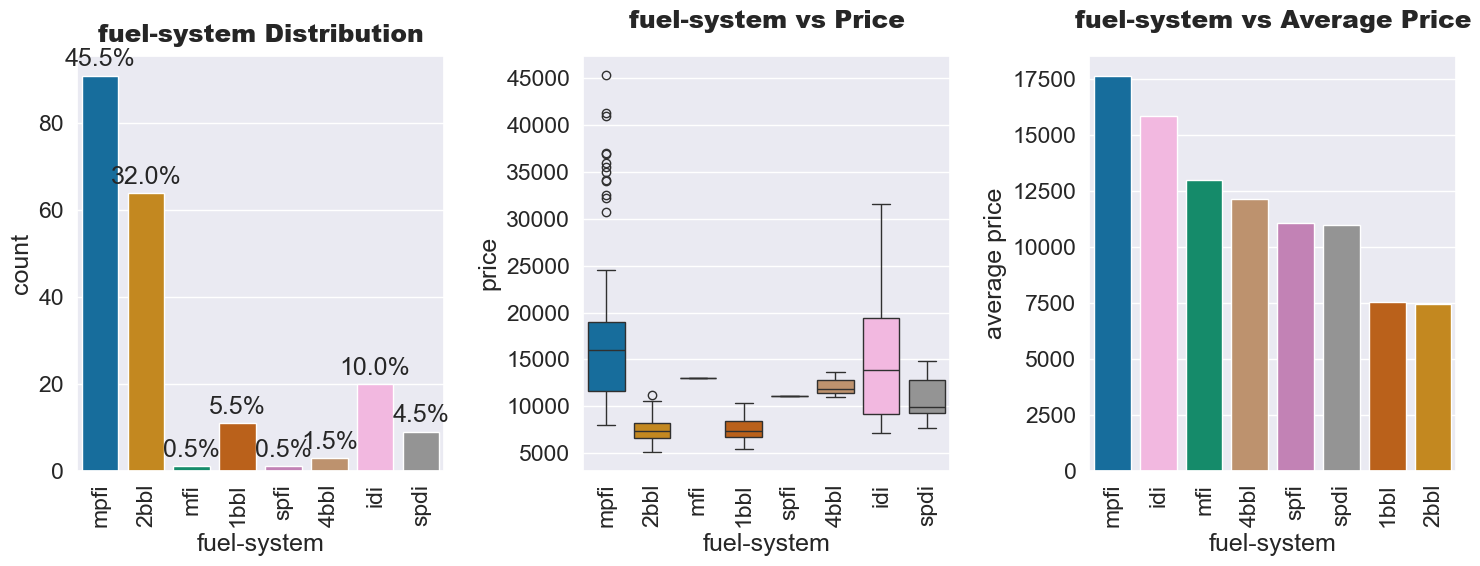

In [55]:
cg("fuel-system")

In [56]:
df_all[df_all["fuel-system"].isin(["mfi","spfi"])]

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
27,3,145,dodge,gas,turbo,two,hatchback,fwd,front,95.9,173.2,66.3,50.2,2811,ohc,four,156,mfi,3.60,3.90,7.0,145.0,5000.0,19,24,12964
42,2,NaN,isuzu,gas,std,two,hatchback,rwd,front,96.0,172.6,65.2,51.4,2734,ohc,four,119,spfi,3.43,3.23,9.2,90.0,5000.0,24,29,11048


### Observations
1. Most of the cars are having mpfi & 2bbl fuelsystems.
2. Cars having mpfi fuel system are the expensive cars followed by idi fuel system cars.
3. There are only one data-point for each mfi and spfi fuelsystem cars. So we can make any further inference.

## 11. Symbolings

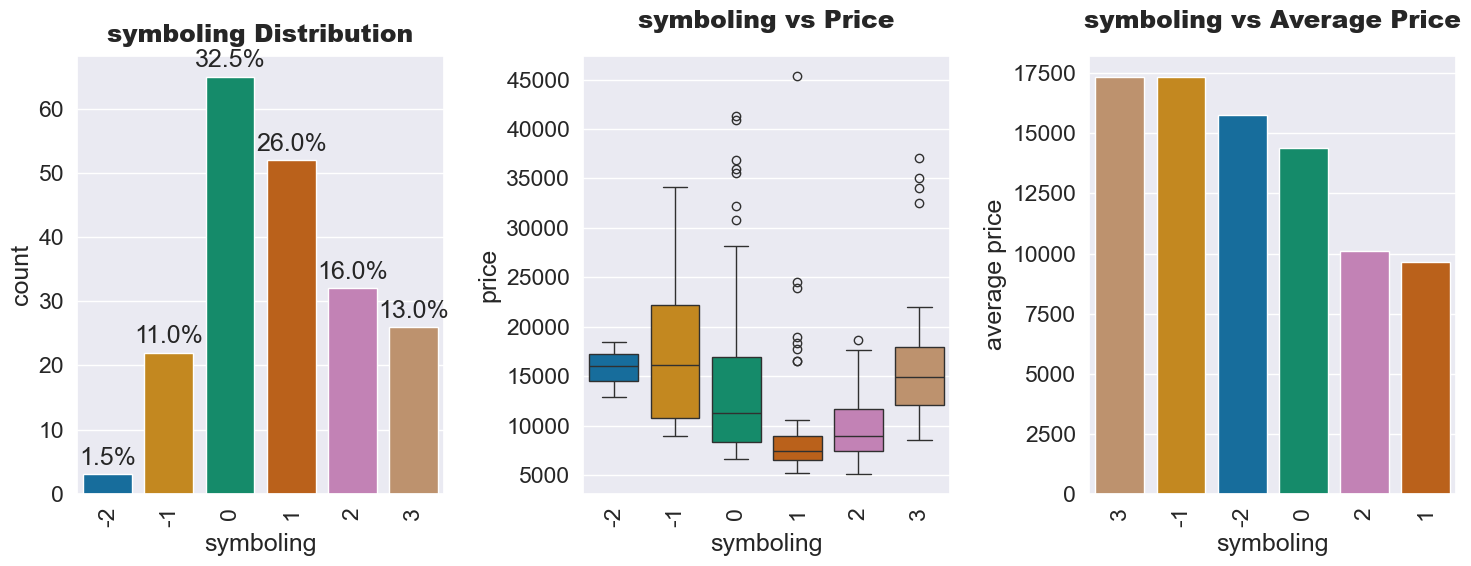

In [57]:
cg('symboling')

## Overview
1. The symboling represents the degree to which the car is riskier than its price suggests.
2. It ranges from -3 to +3, with higher negative values indicating higher risk and higher positive values indicating lower risk.
3. In other words, a car with a symboling of -3 is considered riskier than a car with a symboling of +3, and is likely to have a lower price as a result.

## Observation:
1. Symboling 0 or 1 are mostly preffered by the customers.
2. we can also see that symboling 3,-1,-2 are expensive.

# EDA of numerical column

In [58]:
def ng(cols):
    plt.figure(figsize=(15, 6))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(data=df_all, x=cols, kde=True)
    plt.xticks(rotation=90)
    plt.title(f'Histogram with KDE - {cols}')
    plt.xlabel(cols)
    plt.ylabel("Frequency")

    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(data=df_all, y=cols, color="red")
    plt.title(f'Box Plot of {cols}')
    plt.ylabel(cols)

    plt.tight_layout()
    plt.show()

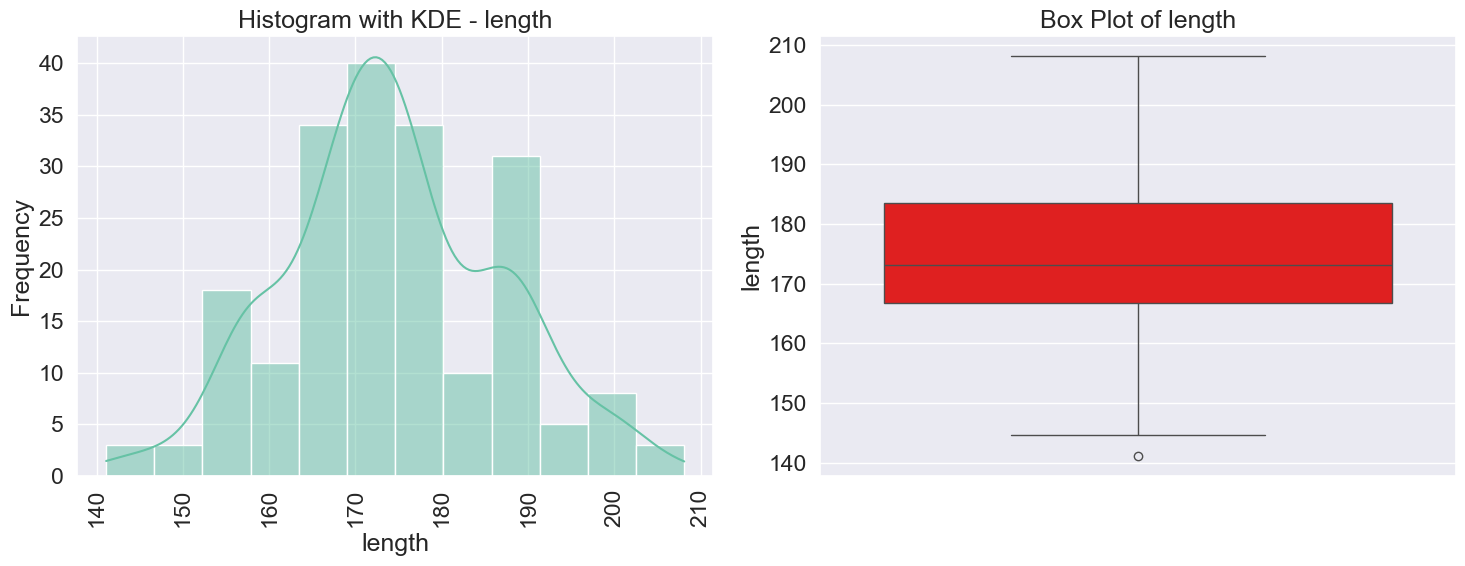

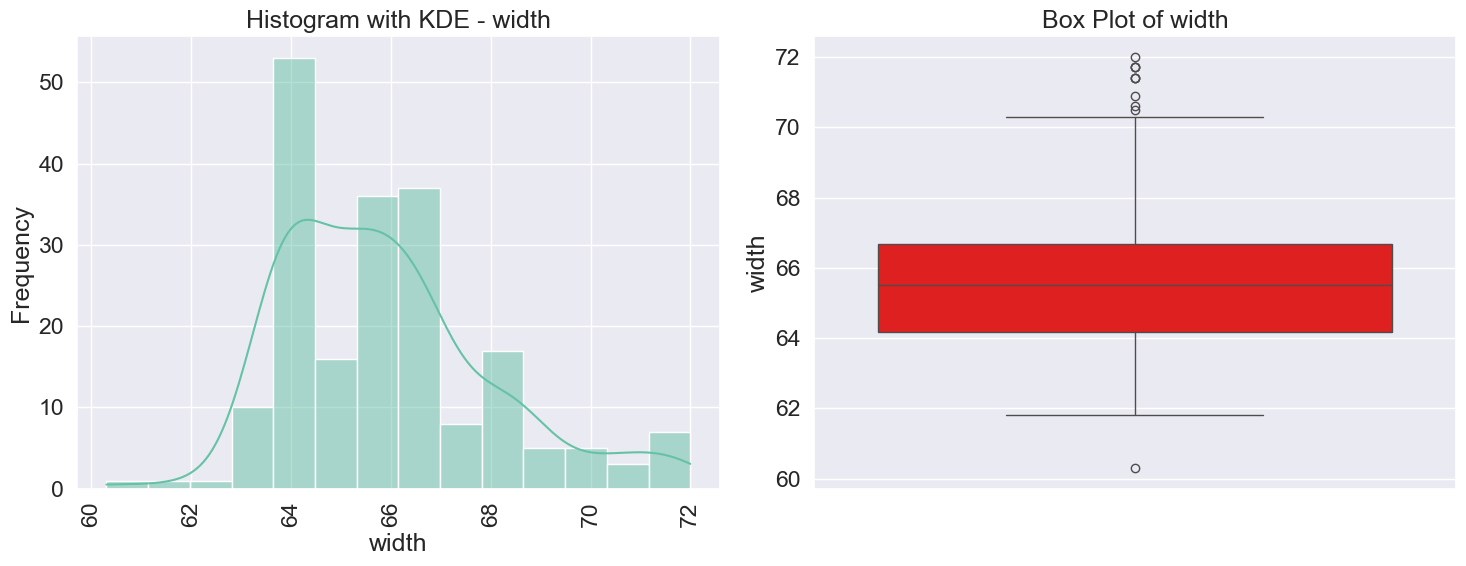

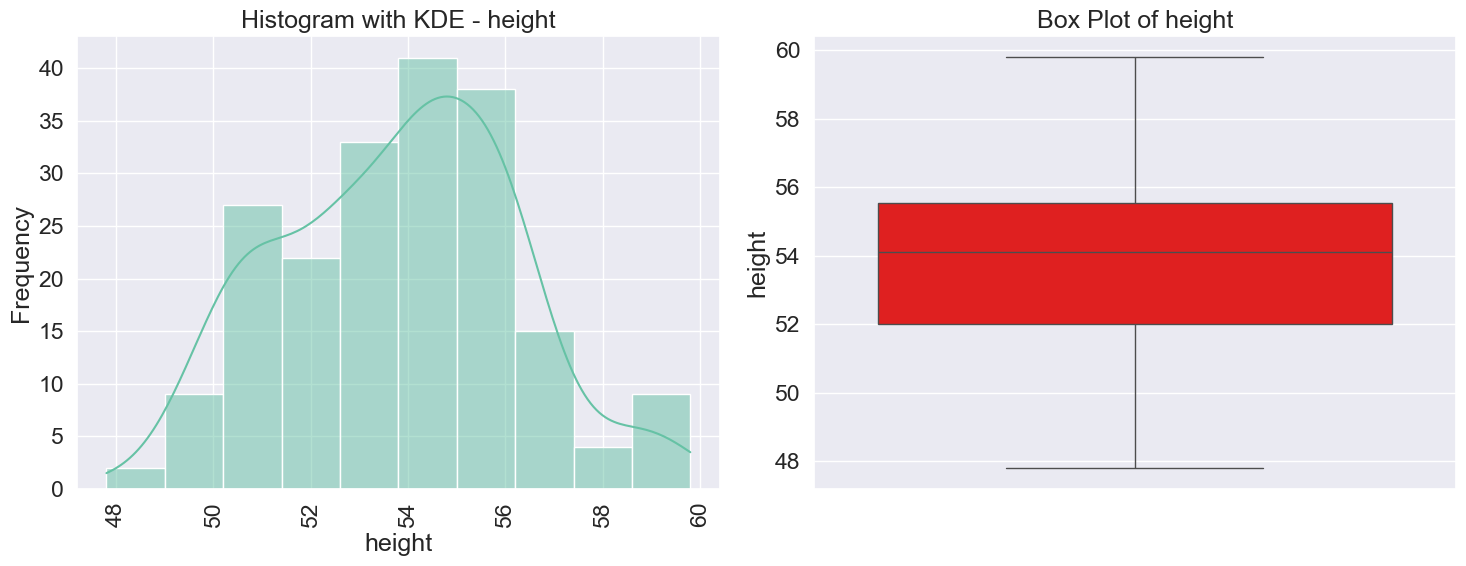

In [59]:
for col in ['length', 'width', 'height']:
    ng(col)

### Observations:-
1. Length and heigth are almost symetrical and dont have any outliers.
2. width is slighlty right skewed and have some outliers

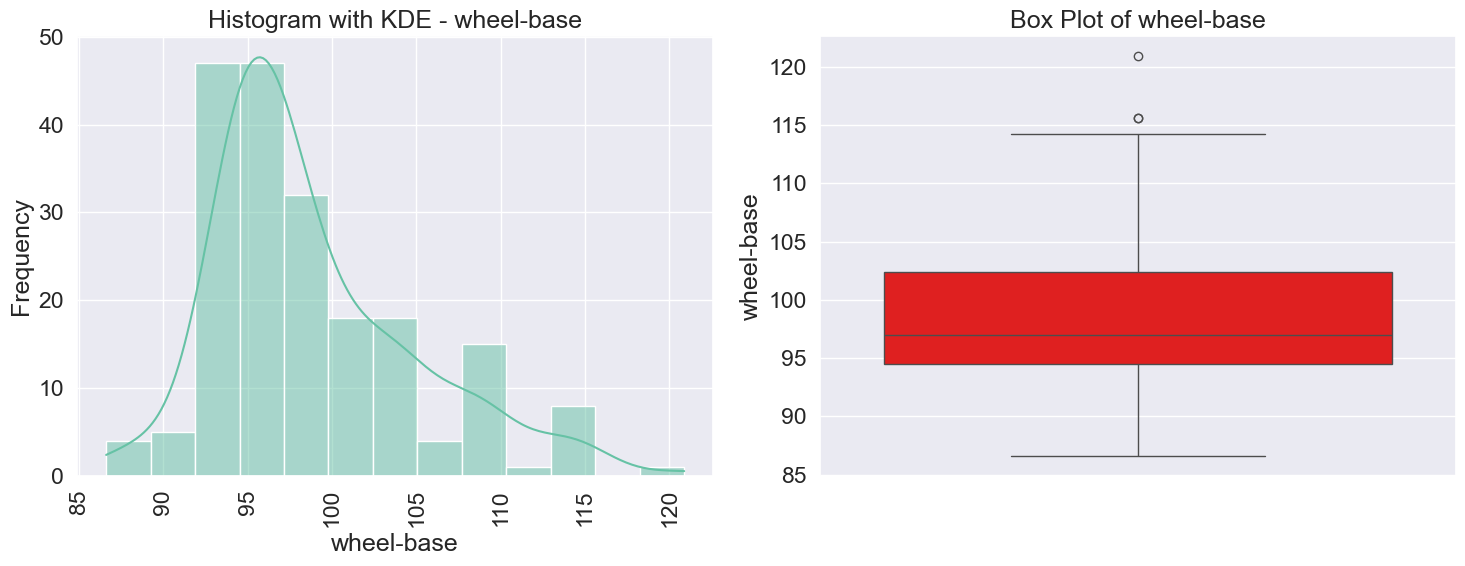

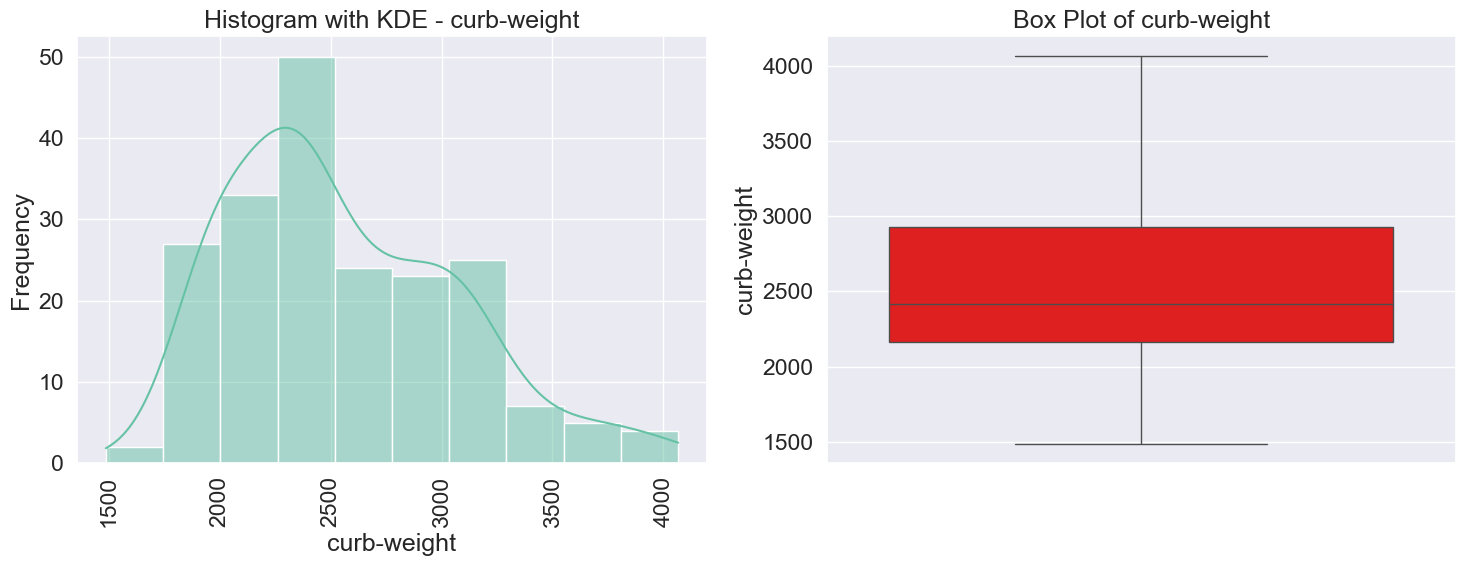

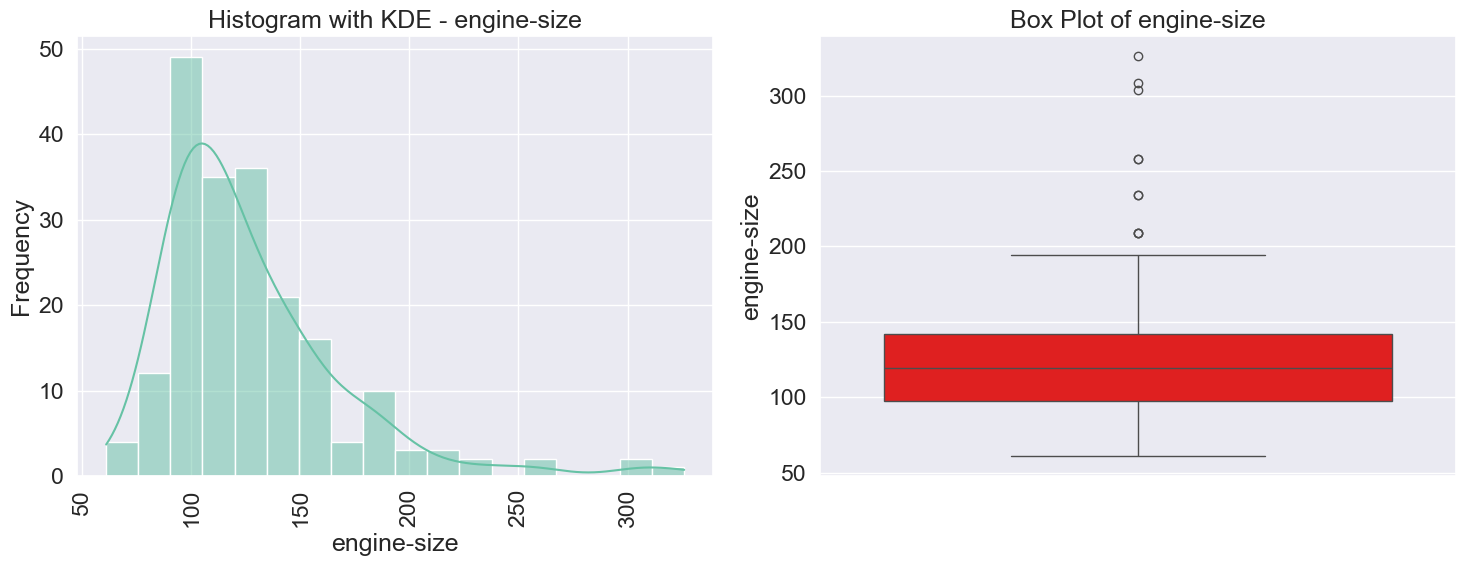

In [60]:
for col in("wheel-base","curb-weight","engine-size"):
    ng(col)

## Observation:-
1. Engine-size is rightly skewed and have few outliers.
2. Curb_weight and wheel-base data are sighlty right skewed and almost no outliers.

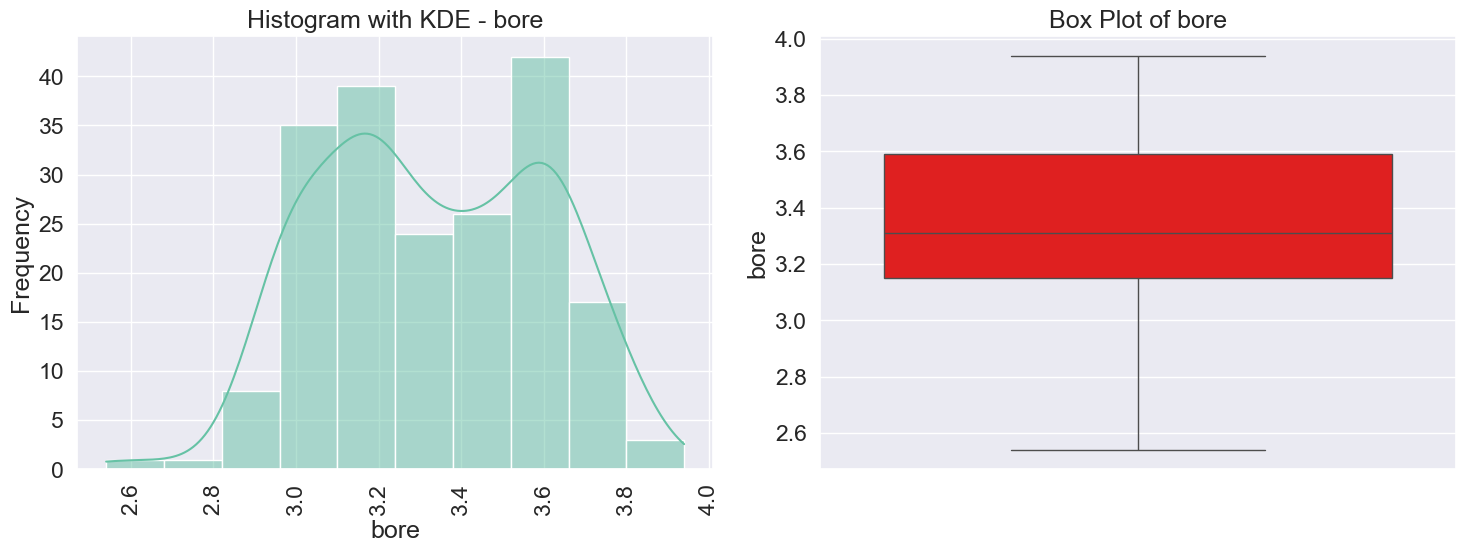

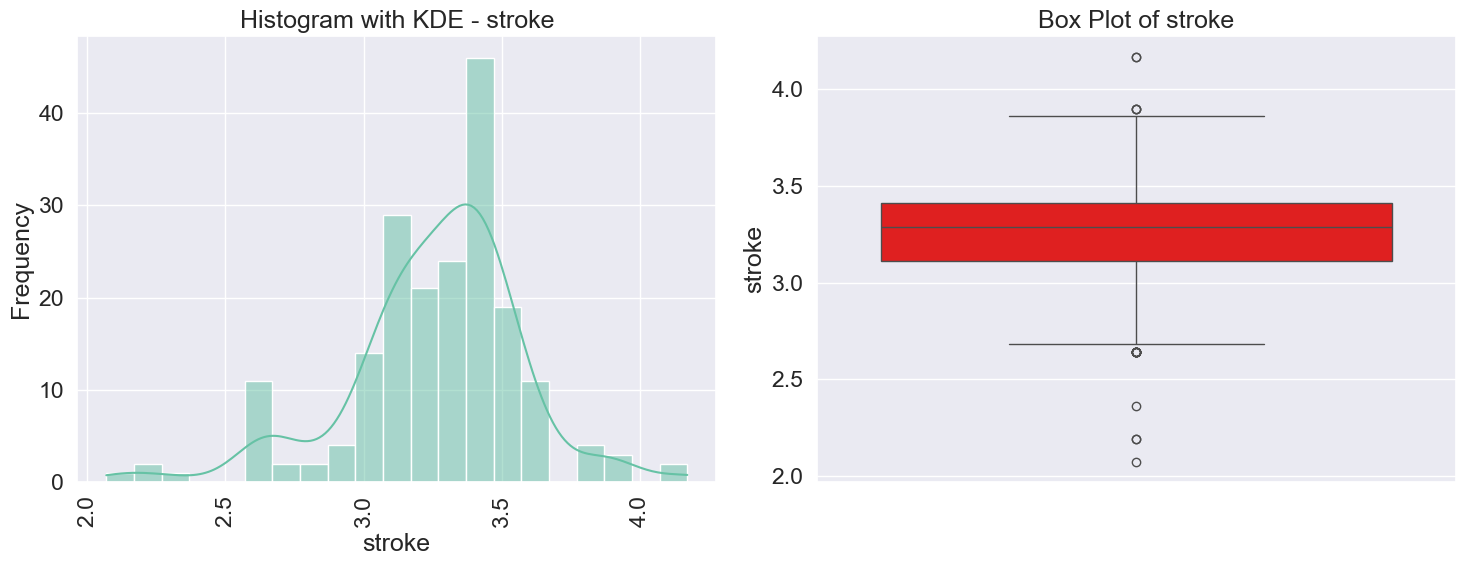

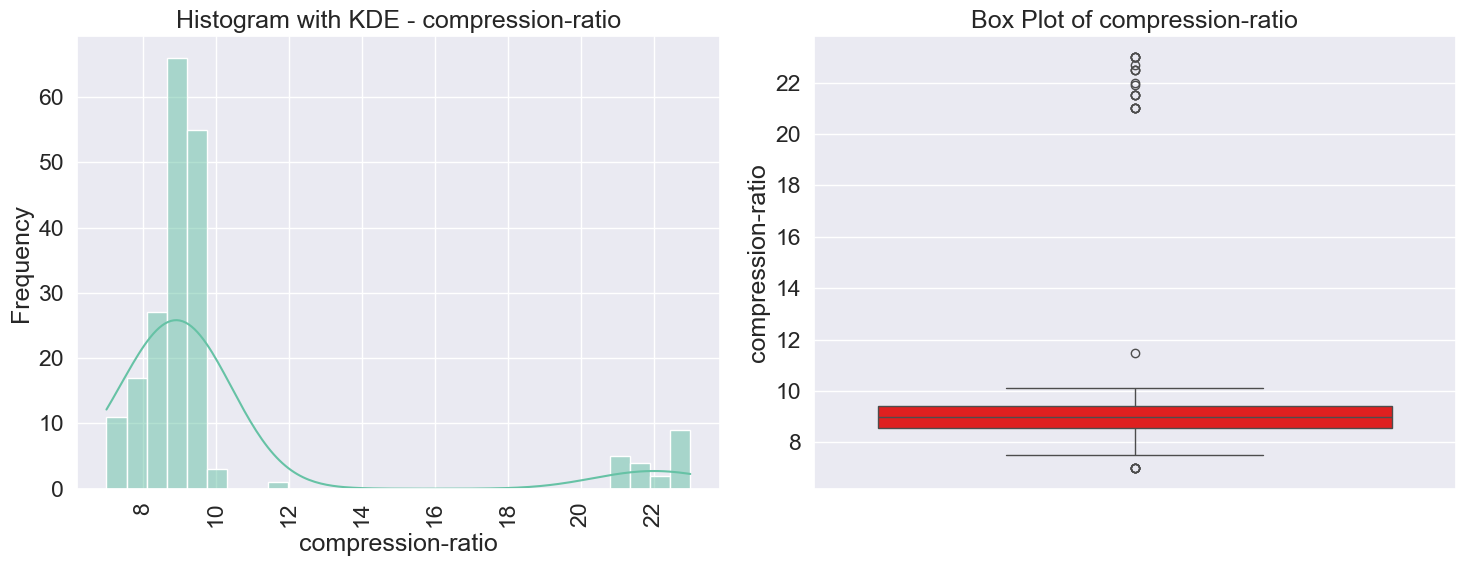

In [61]:
for col in ['bore','stroke','compression-ratio']:
    ng(col)

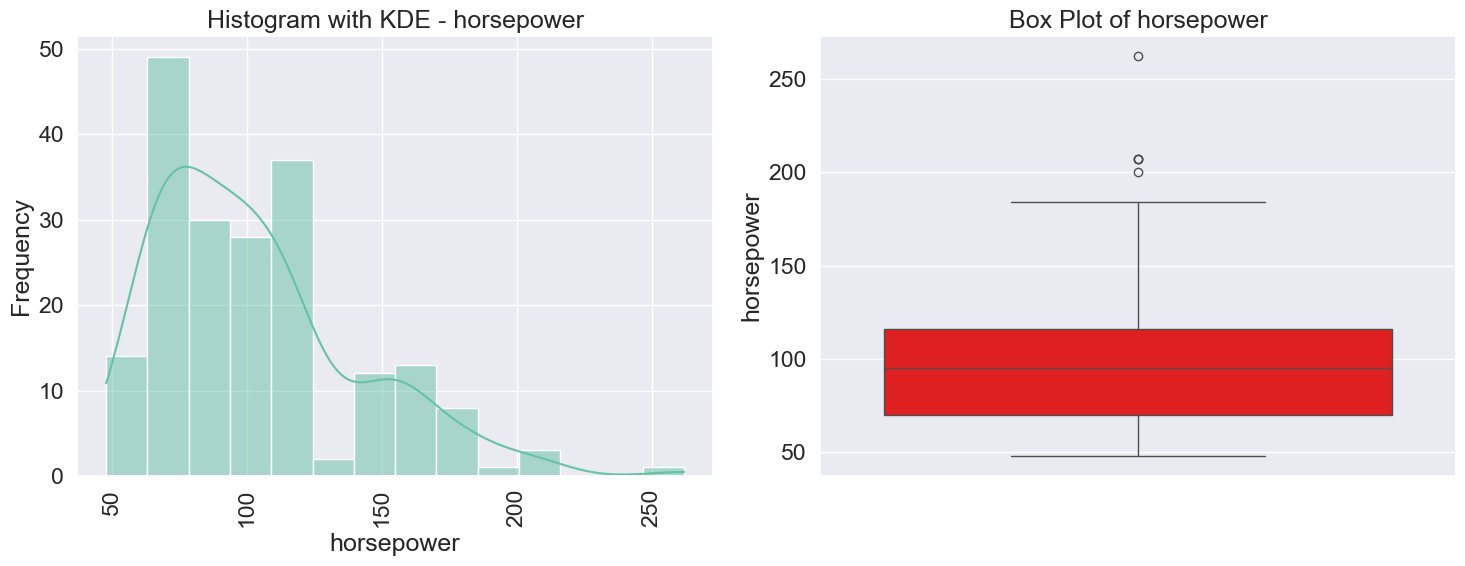

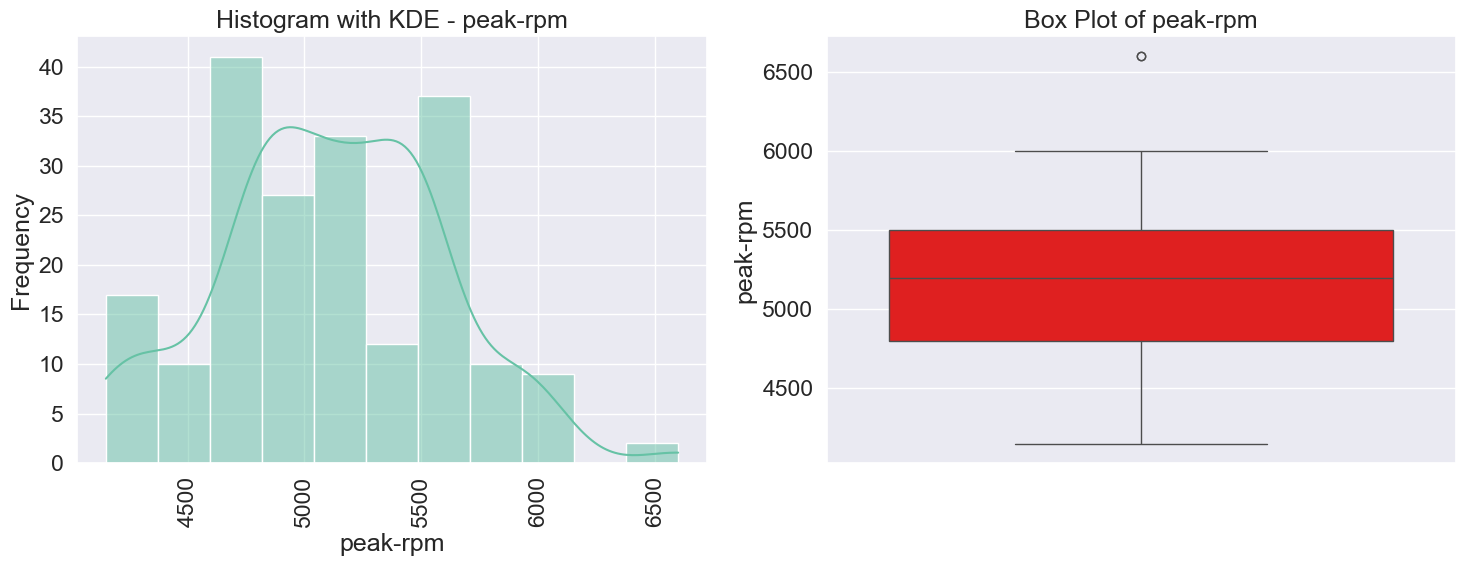

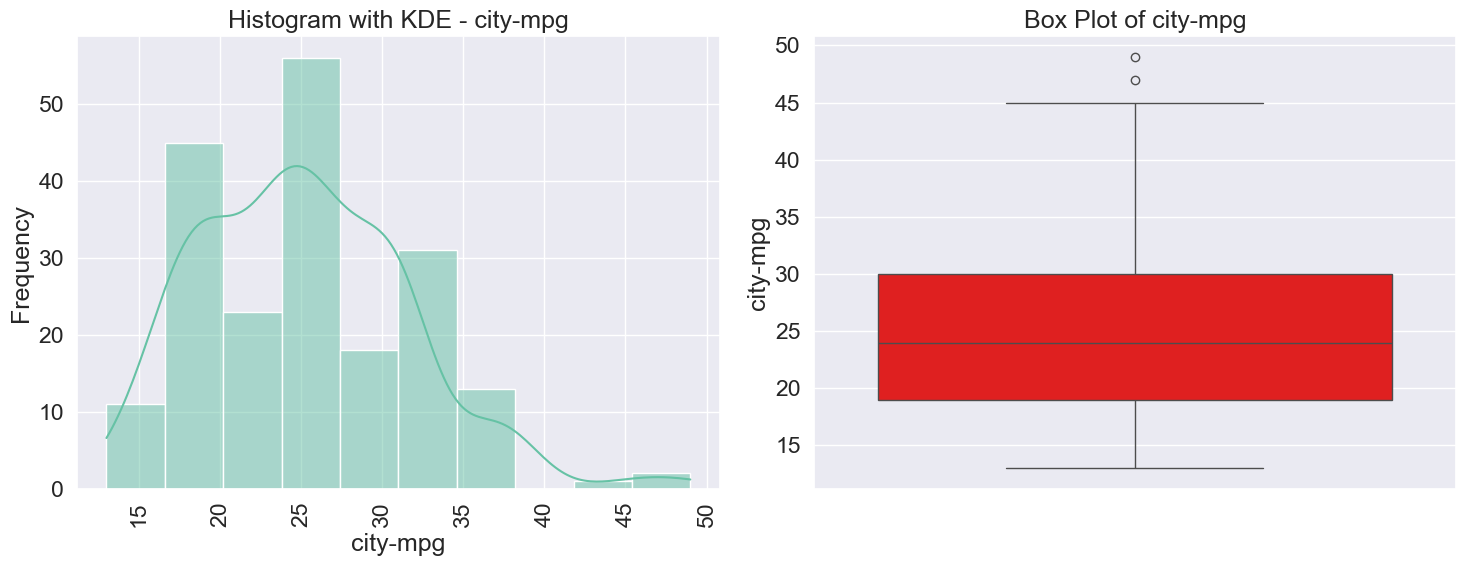

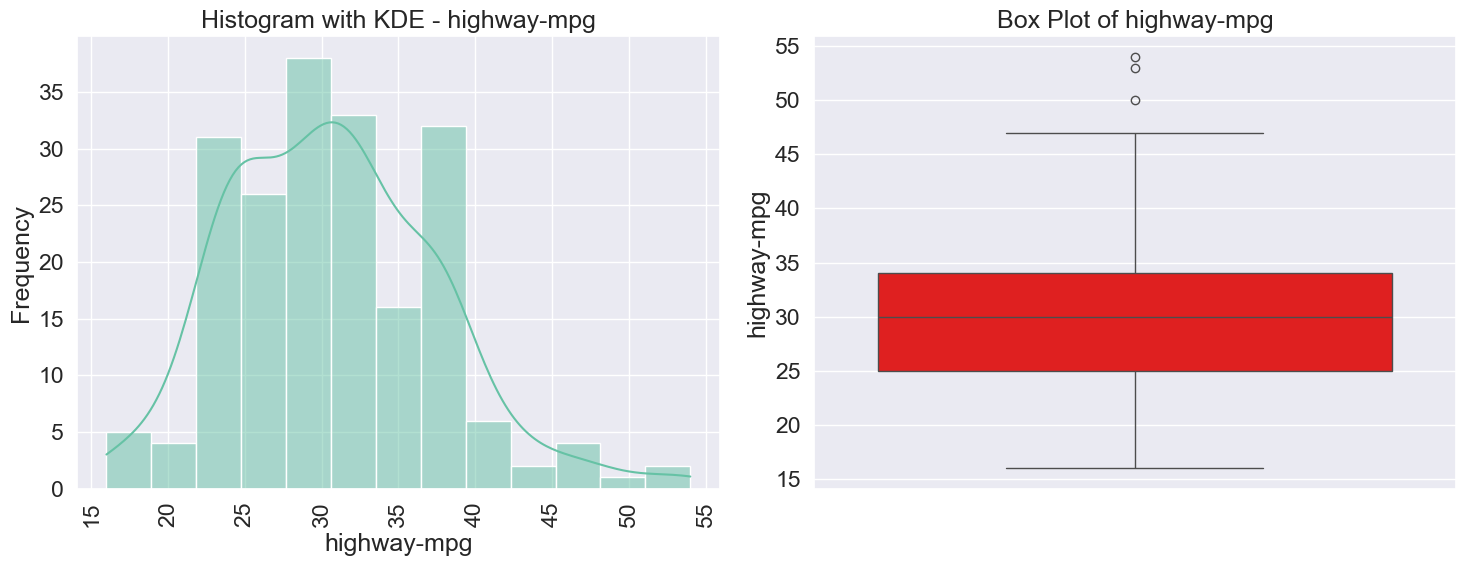

In [62]:
for col in('horsepower',	'peak-rpm',	'city-mpg',	'highway-mpg'):
    ng(col)

## Bivariant Visulization of Numerical column w.r.t price

In [63]:
def sp(cols):
    x=1
    plt.figure(figsize=(16,6))
    for col in cols:
        plt.subplot(1,3,x)
        sns.scatterplot(x=col,y="price",data=df_all,color="teal")
        plt.title(f"{col}vs price")
        plt.tight_layout()
        x+=1

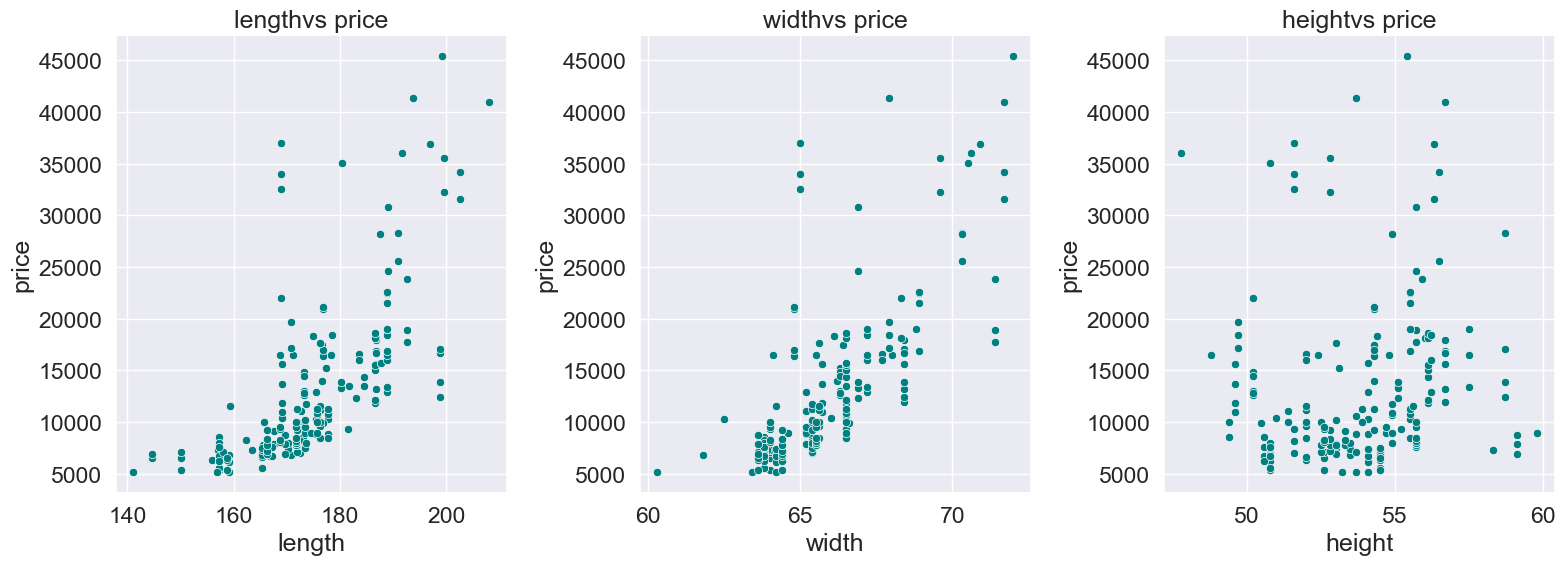

In [64]:
sp(["length","width","height"])

## Insights
1. Only Length and Width are highly corelated to the price of the car.
2. From Heigth we cant make any inference as data points are too scattered.
3. Since height is not affecting the price we can drop it and it is not corelated with other features too.

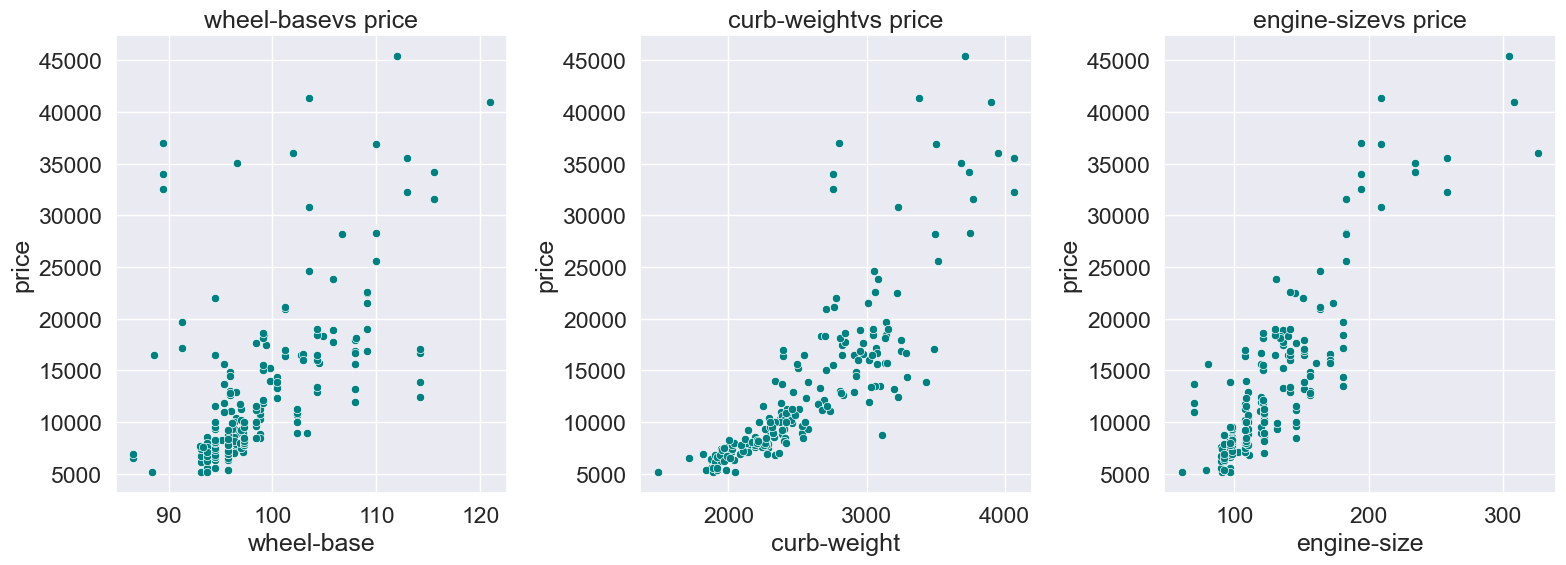

In [65]:
sp(["wheel-base","curb-weight","engine-size"])

## Insights
1. Wheel base ,engine-size and curb weight are corelated to the car price.
2. We cant drop any feature

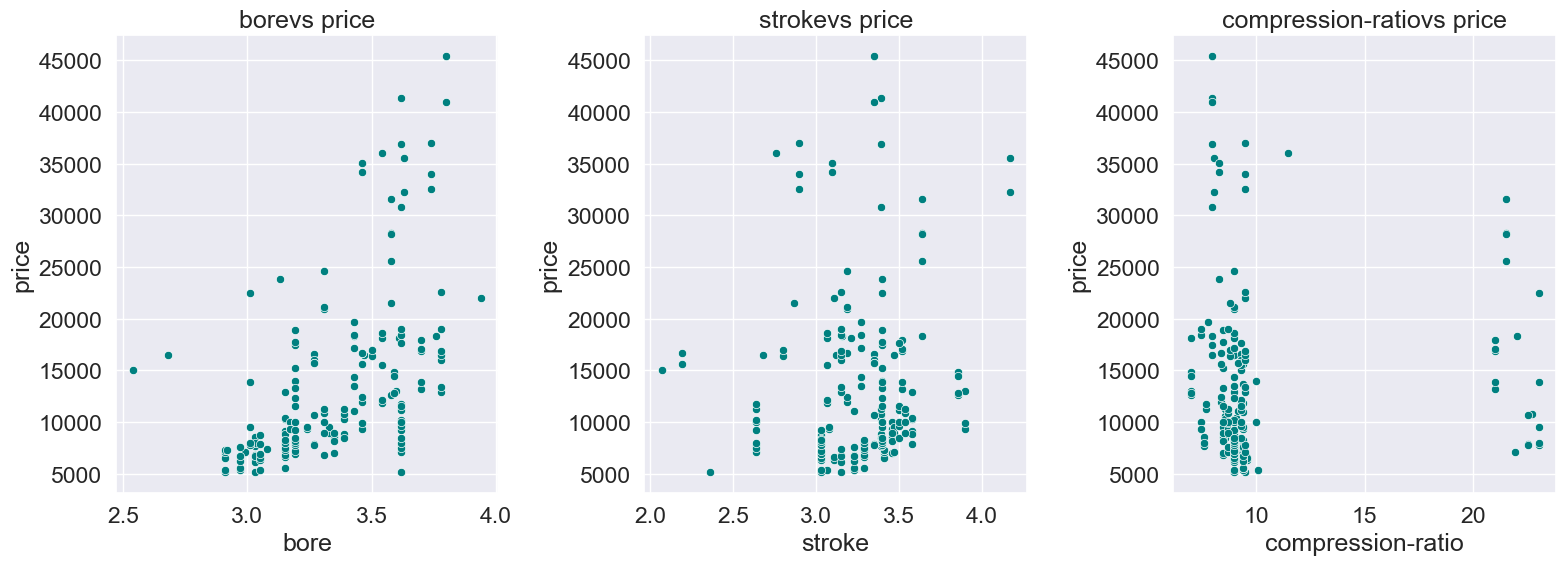

In [66]:
sp(['bore','stroke','compression-ratio'])

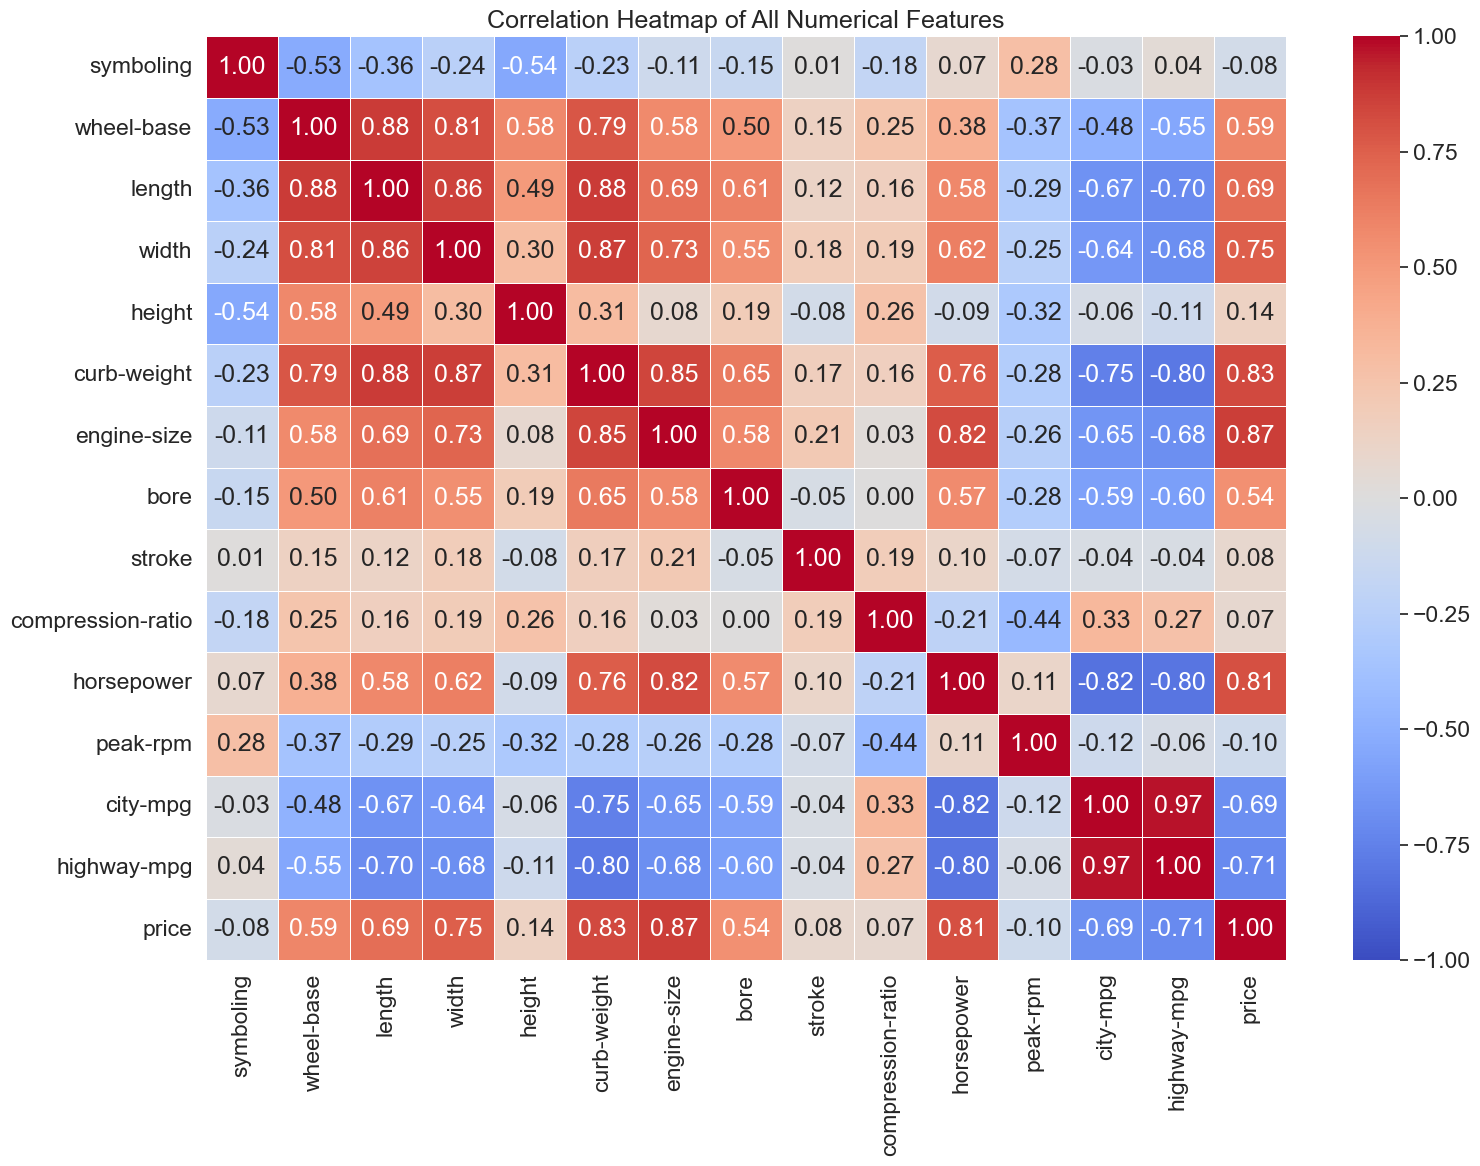

In [67]:
corr = df_all.corr(numeric_only=True)

# Plot heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Correlation Heatmap of All Numerical Features')
plt.tight_layout()
plt.show()

## Insight
1. Only bore is corelated to price.
2. From Stroke vs Price we cant make any inference as the data-points are too scattered.
3. From compression-ratio vs Price we can't make any inference as the data-points are too scattered.
4. Since srtroke and compression ratio is affecting the price , we can drop it.

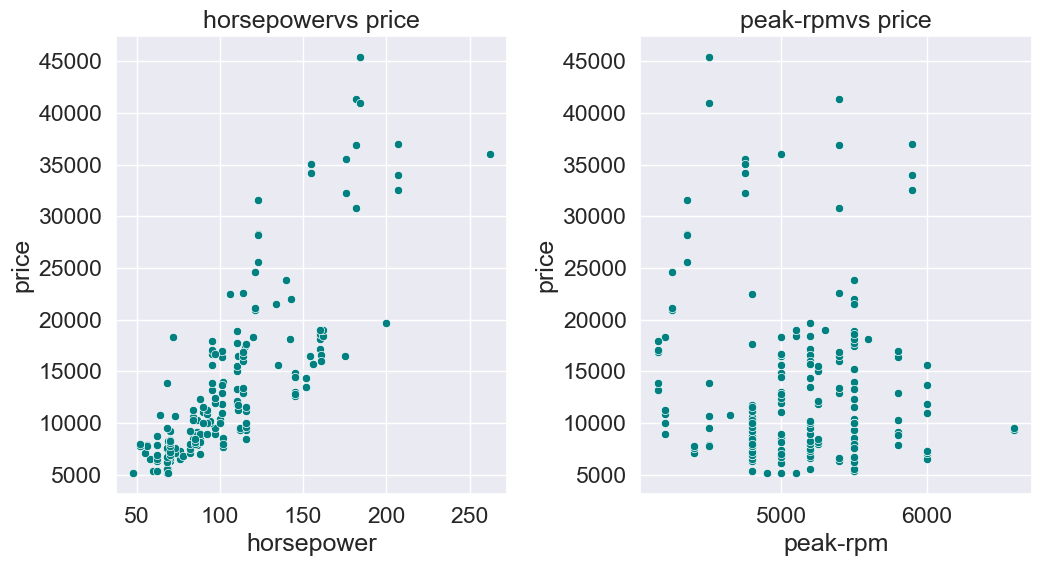

In [68]:
sp(["horsepower","peak-rpm"])

## Insights
1. We can clearly observe that Horsepower is highly correlated with Price. So we can say with the increment in Horsepower the price of cars also increases.
2. From Compressionratio vs Price & Peakrpm vs Price visuals we can't make any inference as the data-points are too scattered.
3. SInce Compressionratio & Peakrpm is not affecting price. So we can drop this features.

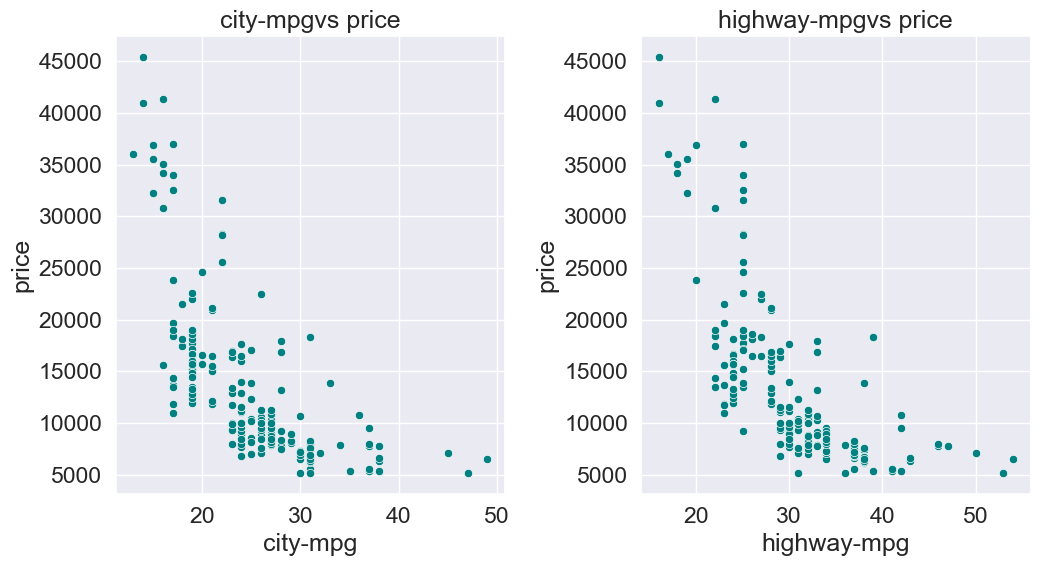

In [69]:
sp(["city-mpg","highway-mpg"])

## Insight
1. We can clearly observe that Citympg & Highwaympg are having negative correlation with the price.
2. So we can say that with the increment in citympg & Highwaympg the price of the cars decreases.
3. So our both Citympg & Highwaympg are useful features for price prediction.
4. In the heatmap we can also see that city-mpg and highway-mpg is highly correlated to each other, so we can make new column of both combines as milege.

# List of all useful numerical features.
1. lenght
2. width
3. wheel-base
4. curb-weight
5. engine size
6. bore
7. horsepower
8. city-mpg
9. highway-mpg
10. price

# List of all useful  categorical feature.
1. car_name
2. fuel-type
3. aspiration
4. num-of-doors
5. body-style
6. drive-wheels
7. engine-type
8. num-of-cylinder
9. fuel-system


In [70]:
df_all.columns

Index(['symboling', 'normalized-losses', 'car_name', 'fuel-type', 'aspiration',
       'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
       'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type',
       'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'price'],
      dtype='object')

# Feature Engineering

1. Since hghway-mpg and city-mpg are highly correlated to each other we can create a new feature as an experiment

In [71]:
df_feature = df_all.copy()

In [72]:
df_feature['average-mpg'] = (
    df_feature['city-mpg'] + df_feature['highway-mpg']
) / 2

df_feature[['city-mpg', 'highway-mpg', 'average-mpg']].head()

,city-mpg,highway-mpg,average-mpg
0,21,27,24.0
1,19,26,22.5
2,24,30,27.0
3,18,22,20.0
4,19,25,22.0


## Deriving a new feature called car range from car_name to reduce weight of our dataset.

In [73]:
R = round(df_all.groupby(["car_name"])["price"].agg(["mean"]),2).T
R

car_name,alfa-romero,audi,bmw,chevrolet,dodge,honda,isuzu,jaguar,mazda,mercedes-benz,mercury,mitsubishi,nissan,peugot,plymouth,porsche,renault,saab,subaru,toyota,volkswagen,volvo
mean,16500.0,17859.17,26118.75,6007.0,7875.44,8184.69,8916.5,34600.0,10652.88,33647.0,16503.0,9239.77,10415.67,15489.09,7963.43,31400.5,9595.0,15223.33,8541.25,9885.81,10077.5,18063.18


## Now add this average value in our datset in form of budget,mid and highend

In [74]:
# Remove car_category to prevent target leakage

df_all = df_all.drop(
    columns=['car_category'],
    errors='ignore'
)

print("car_category removed successfully")

print(df_all.columns.tolist())

car_category removed successfully
['symboling', 'normalized-losses', 'car_name', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']


In [75]:
df_all.sample(12)

,symboling,normalized-losses,car_name,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
172,-1,65,toyota,gas,std,four,hatchback,fwd,front,102.4,175.6,66.5,53.9,2458,ohc,four,122,mpfi,3.31,3.54,8.7,92.0,4200.0,27,32,11248
181,2,94,volkswagen,gas,std,four,sedan,fwd,front,97.3,171.7,65.5,55.7,2275,ohc,four,109,mpfi,3.19,3.40,9.0,85.0,5250.0,27,34,8495
43,0,145,jaguar,gas,std,four,sedan,rwd,front,113.0,199.6,69.6,52.8,4066,dohc,six,258,mpfi,3.63,4.17,8.1,176.0,4750.0,15,19,32250
94,2,168,nissan,gas,std,two,hardtop,fwd,front,95.1,162.4,63.8,53.3,2008,ohc,four,97,2bbl,3.15,3.29,9.4,69.0,5200.0,31,37,8249
131,3,150,saab,gas,turbo,two,hatchback,fwd,front,99.1,186.6,66.5,56.1,2808,dohc,four,121,mpfi,3.54,3.07,9.0,160.0,5500.0,19,26,18150
100,3,194,nissan,gas,std,two,hatchback,rwd,front,91.3,170.7,67.9,49.7,3071,ohcv,six,181,mpfi,3.43,3.27,9.0,160.0,5200.0,19,25,17199
69,0,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,208.1,71.7,56.7,3900,ohcv,eight,308,mpfi,3.80,3.35,8.0,184.0,4500.0,14,16,40960
30,1,101,honda,gas,std,two,hatchback,fwd,front,93.7,150.0,64.0,52.6,1837,ohc,four,79,1bbl,2.91,3.07,10.1,60.0,5500.0,38,42,5399
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
81,1,125,mitsubishi,gas,std,four,sedan,fwd,front,96.3,172.4,65.4,51.6,2365,ohc,four,122,2bbl,3.35,3.46,8.5,88.0,5000.0,25,32,6989


# Data Preprocessing

## Filling null_values

In [76]:
df_all.isnull().sum()

symboling             0
normalized-losses    36
car_name              0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

### We dont need to fill null values of peak-rpm and stroke as they are not required.


In [77]:
import numpy as np
import pandas as pd

# Replace '?' with NaN
df_all.replace('?', np.nan, inplace=True)

# Numerical columns
numerical_cols = [
    'normalized-losses',
    'bore',
    'stroke',
    'horsepower',
    'peak-rpm'
]

# Convert columns into numeric format
for col in numerical_cols:
    df_all[col] = pd.to_numeric(
        df_all[col],
        errors='coerce'
    )

# Fill numerical missing values using median
for col in numerical_cols:
    df_all[col] = df_all[col].fillna(
        df_all[col].median()
    )

# Fill categorical missing values using mode
categorical_cols = ['num-of-doors']

for col in categorical_cols:
    df_all[col] = df_all[col].fillna(
        df_all[col].mode()[0]
    )

print("Missing values handled successfully")

# Check remaining missing values
print(df_all.isnull().sum())

Missing values handled successfully
symboling            0
normalized-losses    0
car_name             0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


In [78]:
df_all.isnull().sum()

symboling            0
normalized-losses    0
car_name             0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

### slecting fetures that we only need.

In [79]:
df_new = df_all[
    [
        'fuel-type',
        'aspiration',
        'num-of-doors',
        'body-style',
        'drive-wheels',
        'engine-type',
        'num-of-cylinders',
        'fuel-system',
        'wheel-base',
        'length',
        'width',
        'curb-weight',
        'engine-size',
        'bore',
        'horsepower',
        'city-mpg',
        'highway-mpg',
        'price'
    ]
].copy()

df_new.head()

,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-type,num-of-cylinders,fuel-system,wheel-base,length,width,curb-weight,engine-size,bore,horsepower,city-mpg,highway-mpg,price
0,gas,std,two,convertible,rwd,dohc,four,mpfi,88.6,168.8,64.1,2548,130,3.47,111.0,21,27,16500
1,gas,std,two,hatchback,rwd,ohcv,six,mpfi,94.5,171.2,65.5,2823,152,2.68,154.0,19,26,16500
2,gas,std,four,sedan,fwd,ohc,four,mpfi,99.8,176.6,66.2,2337,109,3.19,102.0,24,30,13950
3,gas,std,four,sedan,4wd,ohc,five,mpfi,99.4,176.6,66.4,2824,136,3.19,115.0,18,22,17450
4,gas,std,two,sedan,fwd,ohc,five,mpfi,99.8,177.3,66.3,2507,136,3.19,110.0,19,25,15250


In [80]:
df_new.sample(10)

,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-type,num-of-cylinders,fuel-system,wheel-base,length,width,curb-weight,engine-size,bore,horsepower,city-mpg,highway-mpg,price
35,gas,std,two,hatchback,fwd,ohc,four,1bbl,96.5,167.5,65.2,2236,110,3.15,86.0,27,33,7895
18,gas,std,four,sedan,fwd,ohc,four,2bbl,94.5,158.8,63.6,1909,90,3.03,70.0,38,43,6575
13,gas,std,four,sedan,rwd,ohc,six,mpfi,103.5,189.0,66.9,3230,209,3.62,182.0,16,22,30760
180,gas,std,four,sedan,fwd,ohc,four,mpfi,97.3,171.7,65.5,2212,109,3.19,85.0,27,34,8195
184,gas,std,two,convertible,fwd,ohc,four,mpfi,94.5,159.3,64.2,2254,109,3.19,90.0,24,29,11595
107,gas,std,four,sedan,rwd,l,four,mpfi,107.9,186.7,68.4,3075,120,3.46,95.0,19,24,15580
97,gas,std,four,sedan,fwd,ohcv,six,mpfi,100.4,181.7,66.5,3095,181,3.43,152.0,17,22,13499
124,gas,std,two,convertible,rwd,ohcf,six,mpfi,89.5,168.9,65.0,2800,194,3.74,207.0,17,25,37028
160,gas,std,two,sedan,rwd,dohc,four,mpfi,94.5,168.7,64.0,2265,98,3.24,112.0,26,29,9298
8,gas,std,two,sedan,rwd,ohc,four,mpfi,101.2,176.8,64.8,2395,108,3.50,101.0,23,29,16430


## Encoding of all the categorical columns.

In [81]:
# Apply One-Hot Encoding to categorical columns

categorical_cols = [
    "fuel-type",
    "aspiration",
    "num-of-doors",
    "body-style",
    "drive-wheels",
    "engine-type",
    "num-of-cylinders",
    "fuel-system"
]

df_new = pd.get_dummies(
    data=df_new,
    columns=categorical_cols,
    dtype=int
)

df_new.head()

,wheel-base,length,width,curb-weight,engine-size,bore,horsepower,city-mpg,highway-mpg,price,fuel-type_diesel,fuel-type_gas,aspiration_std,aspiration_turbo,num-of-doors_four,num-of-doors_two,body-style_convertible,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon,drive-wheels_4wd,drive-wheels_fwd,drive-wheels_rwd,engine-type_dohc,engine-type_l,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,num-of-cylinders_eight,num-of-cylinders_five,num-of-cylinders_four,num-of-cylinders_six,num-of-cylinders_three,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_1bbl,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
0,88.6,168.8,64.1,2548,130,3.47,111.0,21,27,16500,0,1,1,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
1,94.5,171.2,65.5,2823,152,2.68,154.0,19,26,16500,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
2,99.8,176.6,66.2,2337,109,3.19,102.0,24,30,13950,0,1,1,0,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
3,99.4,176.6,66.4,2824,136,3.19,115.0,18,22,17450,0,1,1,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
4,99.8,177.3,66.3,2507,136,3.19,110.0,19,25,15250,0,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0


In [82]:
df_new.sample(10)

,wheel-base,length,width,curb-weight,engine-size,bore,horsepower,city-mpg,highway-mpg,price,fuel-type_diesel,fuel-type_gas,aspiration_std,aspiration_turbo,num-of-doors_four,num-of-doors_two,body-style_convertible,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon,drive-wheels_4wd,drive-wheels_fwd,drive-wheels_rwd,engine-type_dohc,engine-type_l,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,num-of-cylinders_eight,num-of-cylinders_five,num-of-cylinders_four,num-of-cylinders_six,num-of-cylinders_three,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_1bbl,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
170,102.4,175.6,66.5,2414,122,3.31,92.0,27,32,9988,0,1,1,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
150,95.7,169.7,63.6,3110,92,3.05,62.0,27,32,8778,0,1,1,0,1,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
121,94.5,168.9,68.3,2778,151,3.94,143.0,19,27,22018,0,1,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
59,98.8,177.8,66.5,2443,122,3.39,64.0,36,42,10795,1,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0
136,97.2,172.0,65.4,2145,108,3.62,82.0,32,37,7126,0,1,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
20,93.7,157.3,63.8,1876,90,2.97,68.0,31,38,6377,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
81,96.3,172.4,65.4,2365,122,3.35,88.0,25,32,6989,0,1,1,0,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
65,106.7,187.5,70.3,3495,183,3.58,123.0,22,25,28176,1,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
21,93.7,157.3,63.8,2128,98,3.03,102.0,24,30,7957,0,1,0,1,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
118,93.7,167.3,63.8,2191,98,2.97,68.0,31,38,7609,0,1,1,0,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0


## Feature Scaling of numerical data

In [83]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [84]:
# Select numerical columns for feature scaling

num_cols = [
    'wheel-base',
    'length',
    'width',
    'curb-weight',
    'engine-size',
    'bore',
    'horsepower',
    'city-mpg',
    'highway-mpg'
]

print("Numerical columns selected for scaling")
print(num_cols)

Numerical columns selected for scaling
['wheel-base', 'length', 'width', 'curb-weight', 'engine-size', 'bore', 'horsepower', 'city-mpg', 'highway-mpg']


In [85]:
df_new.sample(5)

,wheel-base,length,width,curb-weight,engine-size,bore,horsepower,city-mpg,highway-mpg,price,fuel-type_diesel,fuel-type_gas,aspiration_std,aspiration_turbo,num-of-doors_four,num-of-doors_two,body-style_convertible,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon,drive-wheels_4wd,drive-wheels_fwd,drive-wheels_rwd,engine-type_dohc,engine-type_l,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,num-of-cylinders_eight,num-of-cylinders_five,num-of-cylinders_four,num-of-cylinders_six,num-of-cylinders_three,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_1bbl,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
133,93.7,156.9,63.4,2050,97,3.62,69.0,31,36,5118,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
43,113.0,199.6,69.6,4066,258,3.63,176.0,15,19,32250,0,1,1,0,1,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
184,94.5,159.3,64.2,2254,109,3.19,90.0,24,29,11595,0,1,1,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
182,97.3,171.7,65.5,2319,97,3.01,68.0,37,42,9495,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0
145,95.7,158.7,63.6,1985,92,3.05,62.0,35,39,5348,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0


# Setting x and y for model testing

In [86]:
x = df_new.drop(columns=["price"])
y = df_new["price"]

In [87]:
x.shape

(200, 44)

In [88]:
y.shape

(200,)

In [89]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [90]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train = x_train.copy()
x_test = x_test.copy()

# Convert numerical columns to float
x_train[num_cols] = x_train[num_cols].astype(float)
x_test[num_cols] = x_test[num_cols].astype(float)

# Scale training and testing data
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

print("Training data scaling completed")
print("Testing data scaling completed")

Training data scaling completed
Testing data scaling completed


In [91]:
print("x_train - >  ",x_train.shape)
print("x_test - >  ",x_test.shape)
print("y_train - >  ",y_train.shape)
print("y_test - >  ",y_test.shape)

x_train - >   (160, 44)
x_test - >   (40, 44)
y_train - >   (160,)
y_test - >   (40,)


In [92]:
%pip install catboost
%pip install xgboost
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_squared_error

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [93]:
training_score = []
testing_score = []
difference = []

def model_prediction(model):
    model.fit(x_train,y_train)
    x_train_pred = model.predict(x_train)
    x_test_pred= model.predict(x_test)
    r_train = r2_score(y_train,x_train_pred)*100
    r_test = r2_score(y_test,x_test_pred)*100
    
    training_score.append([r_train])
    testing_score.append([r_test])
    difference.append(r_train - r_test)
    print(f"r2_Score of {model} model on Training Data is:",r_train)
    print(f"r2_Score of {model} model on Testing Data is:",r_test)
    
    print('absolute error in train and predicted data is :',r_train-r_test)

# Linear-regression Model

In [94]:
model_prediction(LinearRegression())

r2_Score of LinearRegression() model on Training Data is: 91.19570677029675
r2_Score of LinearRegression() model on Testing Data is: 88.31129921750987
absolute error in train and predicted data is : 2.8844075527868824


# Decision Tree Regressor Model

In [95]:
model_prediction(DecisionTreeRegressor())


r2_Score of DecisionTreeRegressor() model on Training Data is: 99.9009137482813
r2_Score of DecisionTreeRegressor() model on Testing Data is: 90.77089882556668
absolute error in train and predicted data is : 9.130014922714622


# Random-Forest-Regressor Model

In [96]:
model_prediction(RandomForestRegressor())

r2_Score of RandomForestRegressor() model on Training Data is: 98.29341386209678
r2_Score of RandomForestRegressor() model on Testing Data is: 96.32609829816815
absolute error in train and predicted data is : 1.9673155639286364


#  Ada-Boost-Regressor Model

In [97]:
model_prediction(AdaBoostRegressor())


r2_Score of AdaBoostRegressor() model on Training Data is: 94.95303549856922
r2_Score of AdaBoostRegressor() model on Testing Data is: 93.53427129612169
absolute error in train and predicted data is : 1.4187642024475338


# Gradient-Boosting-Regressor Mode

In [98]:
model_prediction(GradientBoostingRegressor())

r2_Score of GradientBoostingRegressor() model on Training Data is: 99.18423310752505
r2_Score of GradientBoostingRegressor() model on Testing Data is: 95.95113933536022
absolute error in train and predicted data is : 3.233093772164821


# XGBRegressor Model

In [99]:

model_prediction(XGBRegressor())

r2_Score of XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...) model on Training Data is: 99.9008059501648
r2_Score of XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping

# Cat-Boost-Regressor Model

In [100]:
model_prediction(CatBoostRegressor(verbose=False))

r2_Score of CatBoostRegressor(loss_function='RMSE', verbose=False) model on Training Data is: 99.7028590334834
r2_Score of CatBoostRegressor(loss_function='RMSE', verbose=False) model on Testing Data is: 95.24513844111782
absolute error in train and predicted data is : 4.45772059236559


In [101]:
models = ["Linear Regression","Decision Tree","Random Forest","Ada Boost","Gradient Boost","XGBoost","CatBoost"]

In [102]:
print("Models:", len(models))
print("Training scores:", len(training_score))
print("Testing scores:", len(testing_score))

Models: 7
Training scores: 7
Testing scores: 7


In [103]:
print("Models:", len(models))
print("Training Scores:", len(training_score))
print("Testing Scores:", len(testing_score))
print("Differences:", len(difference))

Models: 7
Training Scores: 7
Testing Scores: 7
Differences: 7


In [104]:
print(models)

['Linear Regression', 'Decision Tree', 'Random Forest', 'Ada Boost', 'Gradient Boost', 'XGBoost', 'CatBoost']


In [105]:
print("Training Scores:", training_score)
print("Testing Scores:", testing_score)
print("Differences:", difference)

Training Scores: [[91.19570677029675], [99.9009137482813], [98.29341386209678], [94.95303549856922], [99.18423310752505], [99.9008059501648], [99.7028590334834]]
Testing Scores: [[88.31129921750987], [90.77089882556668], [96.32609829816815], [93.53427129612169], [95.95113933536022], [96.44840955734253], [95.24513844111782]]
Differences: [2.8844075527868824, 9.130014922714622, 1.9673155639286364, 1.4187642024475338, 3.233093772164821, 3.4523963928222656, 4.45772059236559]


In [106]:
training_score.clear()
testing_score.clear()
difference.clear()

print("All previous scores cleared")
print("Training:", len(training_score))
print("Testing:", len(testing_score))
print("Difference:", len(difference))

All previous scores cleared
Training: 0
Testing: 0
Difference: 0


In [107]:
model_prediction(LinearRegression())

r2_Score of LinearRegression() model on Training Data is: 91.19570677029675
r2_Score of LinearRegression() model on Testing Data is: 88.31129921750987
absolute error in train and predicted data is : 2.8844075527868824


In [108]:
model_prediction(DecisionTreeRegressor())

r2_Score of DecisionTreeRegressor() model on Training Data is: 99.9009137482813
r2_Score of DecisionTreeRegressor() model on Testing Data is: 92.62354812571114
absolute error in train and predicted data is : 7.277365622570159


In [109]:
model_prediction(RandomForestRegressor())

r2_Score of RandomForestRegressor() model on Training Data is: 98.38050624344451
r2_Score of RandomForestRegressor() model on Testing Data is: 96.56665361135336
absolute error in train and predicted data is : 1.8138526320911552


In [110]:
model_prediction(AdaBoostRegressor())

r2_Score of AdaBoostRegressor() model on Training Data is: 94.75764743459352
r2_Score of AdaBoostRegressor() model on Testing Data is: 94.33055614135965
absolute error in train and predicted data is : 0.42709129323387174


In [111]:
model_prediction(GradientBoostingRegressor())

r2_Score of GradientBoostingRegressor() model on Training Data is: 99.18423310752505
r2_Score of GradientBoostingRegressor() model on Testing Data is: 96.44473601517137
absolute error in train and predicted data is : 2.7394970923536732


In [112]:
model_prediction(XGBRegressor())

r2_Score of XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...) model on Training Data is: 99.9008059501648
r2_Score of XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping

In [113]:
model_prediction(CatBoostRegressor())

Learning rate set to 0.03065
0:	learn: 6944.2656064	total: 6.48ms	remaining: 6.47s
1:	learn: 6823.9677818	total: 11.8ms	remaining: 5.9s
2:	learn: 6719.7042809	total: 18ms	remaining: 5.98s
3:	learn: 6585.8596706	total: 23.7ms	remaining: 5.89s
4:	learn: 6478.0575988	total: 34.5ms	remaining: 6.86s
5:	learn: 6362.6734639	total: 52.7ms	remaining: 8.72s
6:	learn: 6239.6291737	total: 59.7ms	remaining: 8.47s
7:	learn: 6136.4438966	total: 67ms	remaining: 8.31s
8:	learn: 6018.1818350	total: 76.1ms	remaining: 8.38s
9:	learn: 5915.1203272	total: 84.3ms	remaining: 8.34s
10:	learn: 5813.0004435	total: 92.8ms	remaining: 8.35s
11:	learn: 5716.3095129	total: 104ms	remaining: 8.6s
12:	learn: 5623.4139594	total: 147ms	remaining: 11.2s
13:	learn: 5520.1739959	total: 168ms	remaining: 11.9s
14:	learn: 5427.5200514	total: 179ms	remaining: 11.7s
15:	learn: 5339.2061446	total: 184ms	remaining: 11.3s
16:	learn: 5255.8339605	total: 201ms	remaining: 11.6s
17:	learn: 5178.7137933	total: 210ms	remaining: 11.5s
18:	

In [114]:
training_score = []
testing_score = []
difference = []

In [115]:
model_prediction(LinearRegression())
model_prediction(DecisionTreeRegressor())
model_prediction(RandomForestRegressor())
model_prediction(AdaBoostRegressor())
model_prediction(GradientBoostingRegressor())
model_prediction(XGBRegressor())
model_prediction(CatBoostRegressor(loss_function='RMSE'))

r2_Score of LinearRegression() model on Training Data is: 91.19570677029675
r2_Score of LinearRegression() model on Testing Data is: 88.31129921750987
absolute error in train and predicted data is : 2.8844075527868824
r2_Score of DecisionTreeRegressor() model on Training Data is: 99.9009137482813
r2_Score of DecisionTreeRegressor() model on Testing Data is: 92.20897954569053
absolute error in train and predicted data is : 7.691934202590772
r2_Score of RandomForestRegressor() model on Training Data is: 98.46126035018426
r2_Score of RandomForestRegressor() model on Testing Data is: 96.34172979447128
absolute error in train and predicted data is : 2.119530555712984
r2_Score of AdaBoostRegressor() model on Training Data is: 95.25267499424137
r2_Score of AdaBoostRegressor() model on Testing Data is: 94.22500422987846
absolute error in train and predicted data is : 1.0276707643629095
r2_Score of GradientBoostingRegressor() model on Training Data is: 99.18423310752505
r2_Score of GradientBoos

In [116]:
print("Models:", len(models))
print("Training Scores:", len(training_score))
print("Testing Scores:", len(testing_score))
print("Differences:", len(difference))

Models: 7
Training Scores: 7
Testing Scores: 7
Differences: 7


In [117]:
print("Models:", len(models))
print("Training Scores:", len(training_score))
print("Testing Scores:", len(testing_score))
print("Differences:", len(difference))

Models: 7
Training Scores: 7
Testing Scores: 7
Differences: 7


In [118]:
df_t = pd.DataFrame({
    "Algorithms": models,
    "Training Score": training_score,
    "Testing Score": testing_score,
    "Difference": difference
})

df_t

,Algorithms,Training Score,Testing Score,Difference
0,Linear Regression,[91.19570677029675],[88.31129921750987],2.884408
1,Decision Tree,[99.9009137482813],[92.20897954569053],7.691934
2,Random Forest,[98.46126035018426],[96.34172979447128],2.119531
3,Ada Boost,[95.25267499424137],[94.22500422987846],1.027671
4,Gradient Boost,[99.18423310752505],[96.20972429347233],2.974509
5,XGBoost,[99.9008059501648],[96.44840955734253],3.452396
6,CatBoost,[99.7028590334834],[95.24513844111782],4.457721


In [119]:
df_t.dtypes

Algorithms         object
Training Score     object
Testing Score      object
Difference        float64
dtype: object

In [120]:
print(df_t.dtypes)

print("\nAlgorithm values:")
print(df_t["Algorithms"].tolist())

print("\nData types:")
print(df_t["Algorithms"].apply(type))

Algorithms         object
Training Score     object
Testing Score      object
Difference        float64
dtype: object

Algorithm values:
['Linear Regression', 'Decision Tree', 'Random Forest', 'Ada Boost', 'Gradient Boost', 'XGBoost', 'CatBoost']

Data types:
0    <class 'str'>
1    <class 'str'>
2    <class 'str'>
3    <class 'str'>
4    <class 'str'>
5    <class 'str'>
6    <class 'str'>
Name: Algorithms, dtype: object


In [121]:
df_t["Training Score"] = pd.to_numeric(
    df_t["Training Score"], errors="coerce"
)

df_t["Testing Score"] = pd.to_numeric(
    df_t["Testing Score"], errors="coerce"
)

print(df_t.dtypes)

Algorithms         object
Training Score    float64
Testing Score     float64
Difference        float64
dtype: object


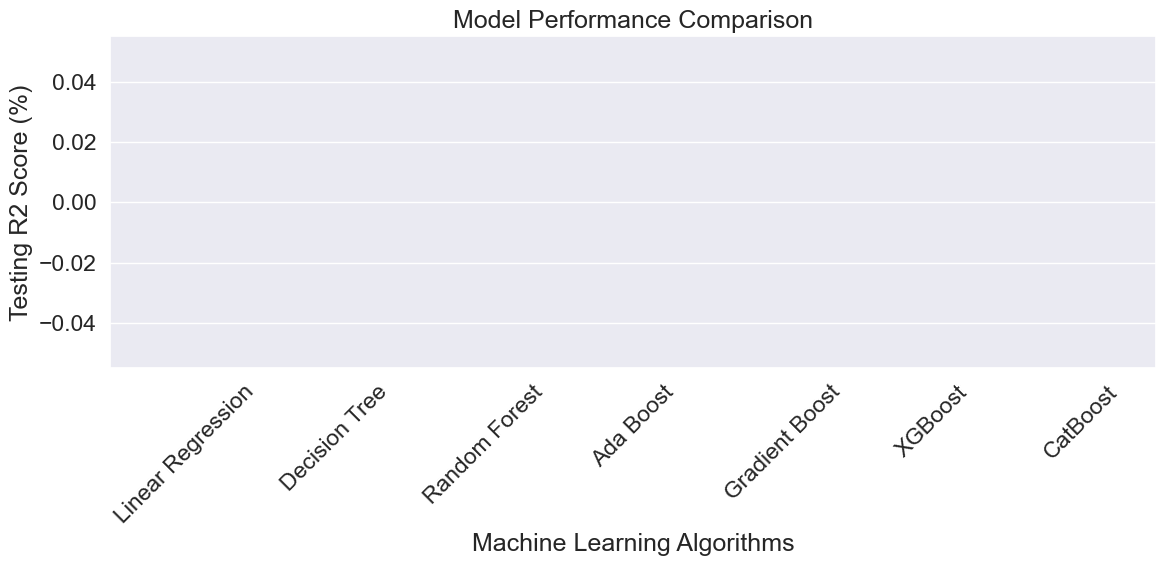

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_t,
    x="Algorithms",
    y="Testing Score"
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Testing R2 Score (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [123]:
df_t_sorted = df_t.sort_values(
    by="Testing Score",
    ascending=False
)

df_t_sorted

,Algorithms,Training Score,Testing Score,Difference
0,Linear Regression,NaN,NaN,2.884408
1,Decision Tree,NaN,NaN,7.691934
2,Random Forest,NaN,NaN,2.119531
3,Ada Boost,NaN,NaN,1.027671
4,Gradient Boost,NaN,NaN,2.974509
5,XGBoost,NaN,NaN,3.452396
6,CatBoost,NaN,NaN,4.457721


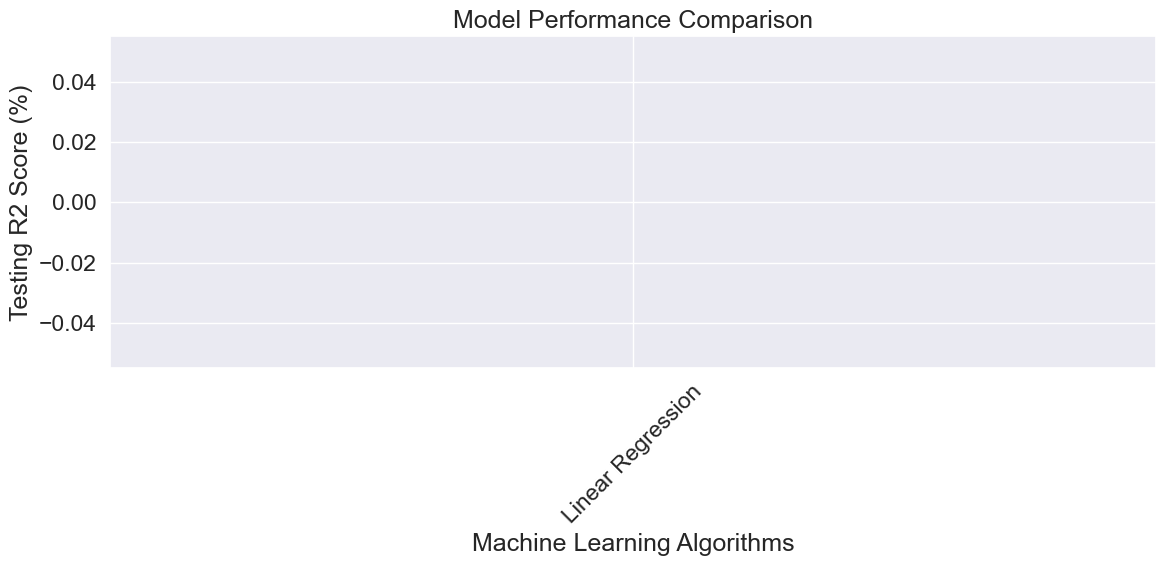

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    df_t_sorted["Algorithms"],
    df_t_sorted["Testing Score"]
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Testing R2 Score (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [125]:
best_model = df_t_sorted.iloc[0]

print("Best Performing Algorithm:")
print("Algorithm:", best_model["Algorithms"])
print("Training Score:", best_model["Training Score"])
print("Testing Score:", best_model["Testing Score"])
print("Difference:", best_model["Difference"])

Best Performing Algorithm:
Algorithm: Linear Regression
Training Score: nan
Testing Score: nan
Difference: 2.8844075527868824


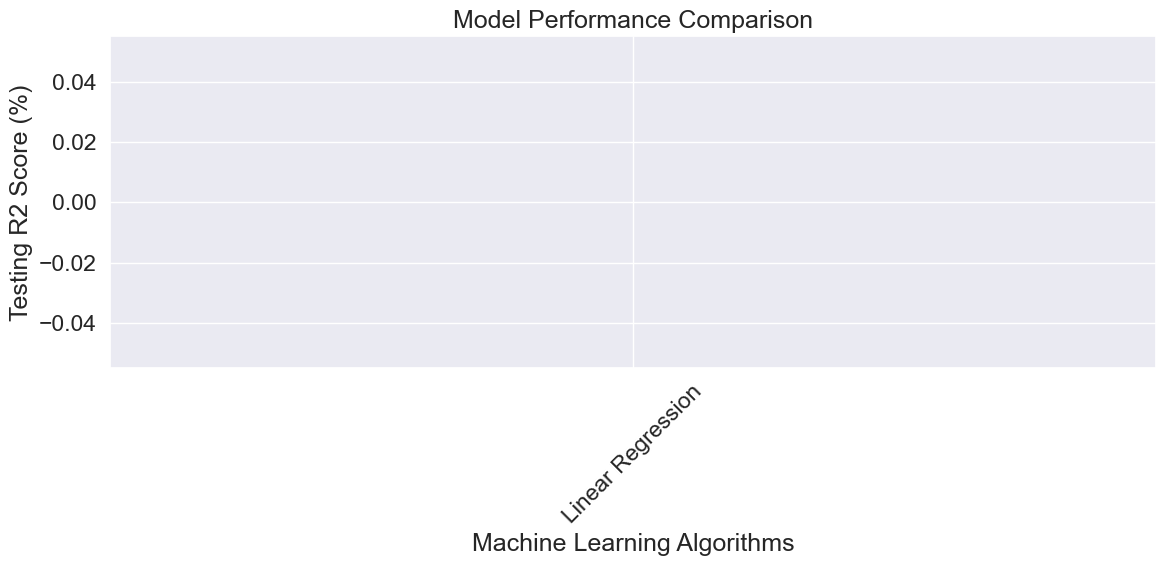

In [126]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    df_t["Algorithms"],
    df_t["Testing Score"]
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Testing R2 Score (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [127]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

best_model = GradientBoostingRegressor()

best_model.fit(x_train, y_train)

y_pred = best_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Model: Gradient Boosting Regressor")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

Model: Gradient Boosting Regressor
MAE: 1576.2469315035773
MSE: 4680101.252967855
RMSE: 2163.3541672522915


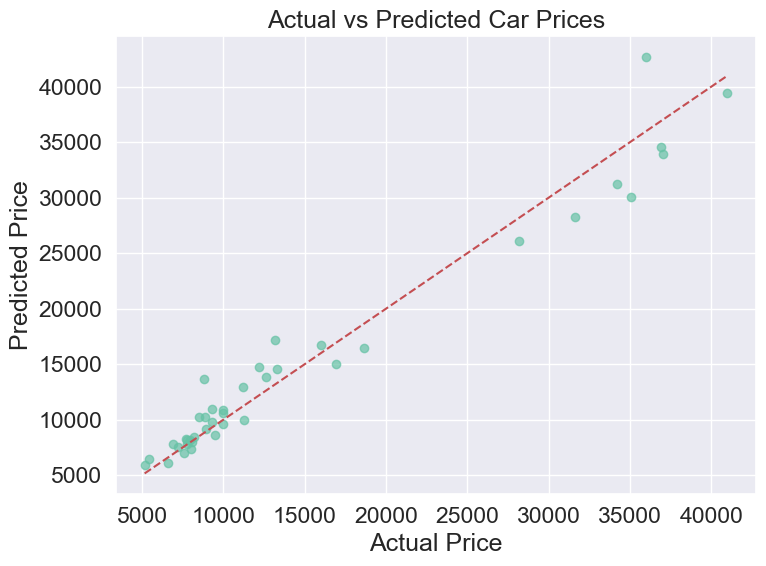

In [128]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.tight_layout()
plt.show()

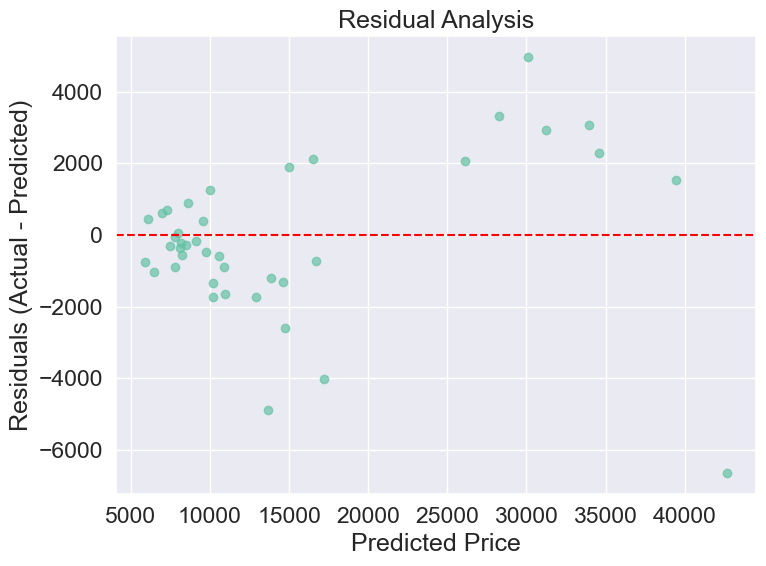

In [129]:
# Calculate prediction errors
residuals = y_test - y_pred

# Plot residuals
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis")

plt.tight_layout()
plt.show()

In [130]:
import joblib

# Save trained model
joblib.dump(best_model, "best_car_price_model.pkl")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

# Save feature column names and order
feature_columns = x_train.columns.tolist()
joblib.dump(feature_columns, "feature_columns.pkl")

print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!


In [131]:
import joblib

# Load saved model
loaded_model = joblib.load("best_car_price_model.pkl")

# Load saved scaler
loaded_scaler = joblib.load("scaler.pkl")

# Load feature columns
loaded_features = joblib.load("feature_columns.pkl")

# Make predictions using loaded model
loaded_predictions = loaded_model.predict(x_test)

print("Saved model loaded successfully!")
print("First 5 predictions:", loaded_predictions[:5])
print("Original prices:", y_test.iloc[:5].values)

Saved model loaded successfully!
First 5 predictions: [ 9125.81107598 34580.85365957  6448.90446751  8011.22307649
 14776.92796334]
Original prices: [ 8949 36880  5399  8058 12170]


## Conclusion

In this project, we developed a Machine Learning model to predict car prices.

### Work Performed
- Loaded and explored the car price dataset.
- Handled missing values.
- Performed data cleaning and preprocessing.
- Applied categorical encoding and feature scaling.
- Split the dataset into training and testing data.
- Trained and compared multiple Machine Learning algorithms.
- Evaluated the best-performing model using R² Score, MAE, MSE, and RMSE.
- Visualized actual vs predicted prices and analysed residuals.
- Saved the trained model using Joblib.

### Final Result
Gradient Boosting Regressor was selected based on the model comparison results.

The model can estimate car prices based on the input features.

# COMPLETE DATA ANALYSIS REPORT

## 1. Project Overview

The main objective of this project is to analyze automobile
data and understand how different car features affect car prices.

## 2. Dataset Description

The dataset contains automobile information such as:
- Car Name
- Fuel Type
- Body Style
- Engine Type
- Engine Size
- Horsepower
- Curb Weight
- Mileage
- Price

## 3. Dataset Dimensions

The dataset contains 205 rows and 26 columns.

## 4. Target Variable

Price is the target variable.

## 5. Independent Variables

The remaining car features are used as independent variables
to understand and predict automobile prices.

## 6. Missing Values Analysis

During data inspection, missing values were identified
in the dataset.

Some missing values were represented using the symbol '?'.
These values were converted into NaN using Pandas.

The missing values were analyzed using isnull().sum().

### Handling Missing Values

Missing values were handled during the data preprocessing
stage using suitable techniques.

This step helps improve data quality and prepare the
dataset for machine learning.

## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand
the characteristics and patterns in the automobile dataset.

The following analysis techniques were used:

### 1. Univariate Analysis
- Analyzed individual numerical features.
- Examined the distribution of categorical features.
- Used histograms and count plots.

### 2. Bivariate Analysis
- Studied the relationship between car features and price.
- Used scatter plots to understand numerical relationships.

### 3. Correlation Analysis
- Used a correlation heatmap to examine relationships
  between numerical variables.
- Identified features that may be useful for price prediction.

### 4. Data Visualization
Matplotlib and Seaborn were used to visualize the data
and understand important patterns.

## 8. Data Preprocessing

Data preprocessing was performed to prepare the dataset
for machine learning model development.

The following techniques were applied:

### 1. Missing Value Handling
Missing values were identified and handled during
data cleaning.

### 2. Categorical Encoding
Categorical variables were converted into numerical
format using One-Hot Encoding.

### 3. Feature Selection
The independent variables were separated from the
target variable (price).

### 4. Train-Test Split
The dataset was divided into training and testing sets
using an 80:20 ratio.

### 5. Feature Scaling
StandardScaler was used to scale numerical features.
The scaler was fitted on the training data and applied
to the testing data.

## 9. Data Analysis Findings

The exploratory data analysis helped to understand
the automobile dataset and its important features.

The analysis focused on:

- Distribution of automobile prices.
- Differences between car body styles.
- Relationship between engine size and price.
- Relationship between horsepower and price.
- Impact of curb weight on automobile prices.
- Correlation between numerical features.

These observations help identify important factors
that influence automobile pricing.

## 10. Data Analysis Conclusion

The automobile dataset was analyzed using Python libraries
such as Pandas, NumPy, Matplotlib and Seaborn.

Data cleaning, exploratory data analysis and visualization
helped in understanding the dataset.

The analysis provided insights into automobile features
and their relationship with car prices.

These findings are useful for developing machine learning
models to predict automobile prices.

# MODEL COMPARISON REPORT

## 1. Objective

The objective is to compare different machine learning
regression models to predict automobile prices.

## 2. Models Used

The following regression algorithms were evaluated:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. AdaBoost Regressor
5. Gradient Boosting Regressor
6. XGBoost Regressor
7. CatBoost Regressor

## 3. Evaluation Metrics

The models were evaluated using:

- R² Score
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)

## 4. Model Performance Comparison

The following R² scores were obtained during model evaluation:

| Model | R² Score |
|---|---:|
| Linear Regression | 88.31% |
| Decision Tree Regressor | 83.33% |
| Random Forest Regressor | 96.51% |
| AdaBoost Regressor | 93.30% |
| Gradient Boosting Regressor | 96.79% |
| XGBoost Regressor | 96.44% |
| CatBoost Regressor | 95.25% |

Gradient Boosting Regressor achieved the highest R² score
among the evaluated models.

## 5. Best Model Recommendation

Based on the evaluated R² scores, Gradient Boosting
Regressor achieved the highest performance of 96.79%.

Therefore, Gradient Boosting Regressor is selected
as the best-performing model among the evaluated models.

It is recommended for further evaluation before production
deployment using MAE, MSE, RMSE and validation data.

The final production decision should also consider
prediction errors and model performance on unseen data.

# CHALLENGES FACED REPORT

## 1. Missing Values

*Challenge:*  
The dataset contained missing values represented by '?'.

*Technique Used:*  
Replaced '?' with NaN and identified missing values
using Pandas.

*Reason:*  
To identify and handle incomplete data.

## 2. Categorical Data

*Challenge:*  
Some features contained text values instead of numerical values.

*Technique Used:*  
One-Hot Encoding.

*Reason:*  
Machine learning algorithms require numerical input.

## 3. Feature Scaling

*Challenge:*  
Numerical features had different scales.

*Technique Used:*  
StandardScaler.

*Reason:*  
To bring numerical features to a comparable scale.

## 4. Model Selection

*Challenge:*  
Selecting the best model from multiple regression algorithms.

*Technique Used:*  
Compared models using R² Score, MAE, MSE and RMSE.

*Reason:*  
To identify a model with better prediction performance.

## 5. Target Leakage

*Challenge:*  
The car_category feature was derived from the target variable (price).

*Technique Used:*  
Removed car_category from the independent features.

*Reason:*  
To prevent target information from leaking into model training.